# Problem Statement
Agricultural activities are influenced by seasonal variations in environmental conditions,
farming practices, resource availability and market conditions. As a result, agricultural
performance may differ from one season to another.
However, raw agricultural data does not clearly explain how agricultural performance changes
across seasons or what patterns can be observed in different seasonal conditions.
The problem is to analyze the given agricultural dataset and investigate seasonal differences
in agricultural performance by identifying meaningful patterns, trends, relationships and
variations within the available data.

# Introduction to Dataset
The dataset represents agricultural activities carried out across different seasons,
geographical areas and farming conditions. It contains information related to farming
practices, environmental conditions, crop production, resource usage and economic
performance.

# Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Load the Dataset

In [2]:
df = pd.read_csv('seasonal_agriculture_performance.csv')
print(df)

      Farm_ID           State  District    Crop  Season  Farm_Area_Hectares  \
0     SF10001  Andhra Pradesh    Rajkot   Wheat  Kharif                0.53   
1     SF10002     Maharashtra  Nalgonda   Maize  Kharif                6.53   
2     SF10003       Telangana  Warangal  Pulses    Rabi                4.86   
3     SF10004       Telangana    Indore    Rice  Kharif                4.50   
4     SF10005       Karnataka  Ludhiana   Maize    Zaid                4.21   
...       ...             ...       ...     ...     ...                 ...   
3995  SF13996       Karnataka    Rajkot   Wheat  Kharif                4.72   
3996  SF13997       Karnataka   Krishna  Chilli  Kharif                8.77   
3997  SF13998  Andhra Pradesh     Erode  Pulses    Zaid               10.47   
3998  SF13999          Punjab  Warangal  Cotton  Kharif                1.73   
3999  SF14000          Punjab    Nashik   Wheat  Kharif                3.31   

      Rainfall_mm  Avg_Temperature_C  Humidity_pct 

In [3]:
df.head()

,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,...,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.4,25.7,78.4,5.1,...,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.396,49.9
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.6,23.9,56.4,10.3,...,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.984,33.7
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.2,29.7,65.2,6.3,...,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.160,50.6
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.6,34.1,55.2,6.5,...,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.829,32.3


In [4]:
df.head(10)

,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,...,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.4,25.7,78.4,5.1,...,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.396,49.9
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.6,23.9,56.4,10.3,...,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.984,33.7
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.2,29.7,65.2,6.3,...,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.160,50.6
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.6,34.1,55.2,6.5,...,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.829,32.3
5,SF10006,Gujarat,Raichur,Pulses,Zaid,5.46,356.0,33.6,49.0,8.3,...,0.89,0.72,3.93,68593,302333,269570,-32763,1093,3.596,57.1
6,SF10007,Telangana,Warangal,Wheat,Rabi,8.13,432.2,23.5,50.8,9.5,...,0.87,2.53,20.57,22951,513341,472102,-41239,2368,8.687,31.6
7,SF10008,Tamil Nadu,Ludhiana,Pulses,Kharif,5.34,860.2,29.0,64.9,7.9,...,0.70,1.18,6.30,70042,436200,441265,5065,1704,3.697,54.2
8,SF10009,Karnataka,Guntur,Cotton,Zaid,6.98,624.7,33.4,46.8,7.9,...,0.88,1.53,10.68,70771,525129,755834,230705,5079,2.103,54.7
9,SF10010,Tamil Nadu,Raichur,Chilli,Rabi,13.69,415.8,22.3,57.3,8.6,...,0.70,2.29,31.35,94383,1004072,2958907,1954835,5984,5.239,41.7


In [5]:
df.tail()

,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
3995,SF13996,Karnataka,Rajkot,Wheat,Kharif,4.72,865.4,27.3,51.4,6.3,...,0.74,0.51,2.41,22717,362917,54748,-308169,2016,1.195,45.2
3996,SF13997,Karnataka,Krishna,Chilli,Kharif,8.77,947.5,29.2,85.5,6.1,...,0.80,2.75,24.12,106459,496471,2567791,2071320,5351,4.508,59.7
3997,SF13998,Andhra Pradesh,Erode,Pulses,Zaid,10.47,80.0,35.4,68.5,8.6,...,0.99,0.62,6.49,66860,785632,433921,-351711,3392,1.913,29.2
3998,SF13999,Punjab,Warangal,Cotton,Kharif,1.73,475.0,28.2,61.7,6.4,...,0.98,1.35,2.34,75282,153904,176160,22256,1220,1.918,50.4
3999,SF14000,Punjab,Nashik,Wheat,Kharif,3.31,984.3,25.8,77.2,5.9,...,0.99,2.36,7.81,28812,263872,225022,-38850,1800,4.339,62.3


In [6]:
df.tail(10)

,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
3990,SF13991,Tamil Nadu,Indore,Cotton,Kharif,6.58,1072.3,28.0,79.6,7.3,...,0.70,1.62,10.66,72931,388777,777444,388667,6259,1.703,41.1
3991,SF13992,Telangana,Rajkot,Chilli,Zaid,2.04,338.8,34.4,69.0,7.5,...,0.82,1.07,2.18,80847,137231,176246,39015,854,2.553,41.8
3992,SF13993,Karnataka,Rajkot,Groundnut,Rabi,2.03,579.9,20.4,56.5,8.0,...,0.66,1.61,3.27,58117,139340,190043,50703,1416,2.309,38.6
3993,SF13994,Gujarat,Rajkot,Cotton,Rabi,13.48,308.9,25.0,70.8,8.1,...,0.89,1.33,17.93,71268,1053465,1277835,224370,10589,1.693,43.7
3994,SF13995,Maharashtra,Ludhiana,Wheat,Kharif,9.20,1243.8,27.5,66.5,7.4,...,0.70,2.18,20.06,23314,618838,467679,-151159,5577,3.597,67.1
3995,SF13996,Karnataka,Rajkot,Wheat,Kharif,4.72,865.4,27.3,51.4,6.3,...,0.74,0.51,2.41,22717,362917,54748,-308169,2016,1.195,45.2
3996,SF13997,Karnataka,Krishna,Chilli,Kharif,8.77,947.5,29.2,85.5,6.1,...,0.80,2.75,24.12,106459,496471,2567791,2071320,5351,4.508,59.7
3997,SF13998,Andhra Pradesh,Erode,Pulses,Zaid,10.47,80.0,35.4,68.5,8.6,...,0.99,0.62,6.49,66860,785632,433921,-351711,3392,1.913,29.2
3998,SF13999,Punjab,Warangal,Cotton,Kharif,1.73,475.0,28.2,61.7,6.4,...,0.98,1.35,2.34,75282,153904,176160,22256,1220,1.918,50.4
3999,SF14000,Punjab,Nashik,Wheat,Kharif,3.31,984.3,25.8,77.2,5.9,...,0.99,2.36,7.81,28812,263872,225022,-38850,1800,4.339,62.3


# Checking Rows and Columns

In [10]:
df.iloc[10]

Farm_ID                              SF10011
State                            Maharashtra
District                             Krishna
Crop                                   Wheat
Season                                  Rabi
Farm_Area_Hectares                       4.7
Rainfall_mm                            390.8
Avg_Temperature_C                       24.5
Humidity_pct                            43.5
Sunlight_Hours_Day                       7.8
Soil_pH                                 5.93
Soil_Moisture_pct                       25.2
Nitrogen_kg_ha                         137.9
Phosphorus_kg_ha                        31.4
Potassium_kg_ha                         70.0
Irrigation_Method                  Sprinkler
Fertilizer_kg_ha                       224.4
Pesticide_Litre_ha                       5.9
Seed_Quality_Score                      0.89
Yield_Tonnes_Ha                         1.44
Production_Tonnes                       6.77
Market_Price_INR_Tonne                 20806
Total_Cost

In [11]:
df.columns

Index(['Farm_ID', 'State', 'District', 'Crop', 'Season', 'Farm_Area_Hectares',
       'Rainfall_mm', 'Avg_Temperature_C', 'Humidity_pct',
       'Sunlight_Hours_Day', 'Soil_pH', 'Soil_Moisture_pct', 'Nitrogen_kg_ha',
       'Phosphorus_kg_ha', 'Potassium_kg_ha', 'Irrigation_Method',
       'Fertilizer_kg_ha', 'Pesticide_Litre_ha', 'Seed_Quality_Score',
       'Yield_Tonnes_Ha', 'Production_Tonnes', 'Market_Price_INR_Tonne',
       'Total_Cost_INR', 'Revenue_INR', 'Profit_INR', 'Water_Used_m3',
       'Water_Efficiency_t_per_1000m3', 'Disease_Pest_Risk_pct'],
      dtype='object')

In [12]:
df.columns.to_list()

['Farm_ID',
 'State',
 'District',
 'Crop',
 'Season',
 'Farm_Area_Hectares',
 'Rainfall_mm',
 'Avg_Temperature_C',
 'Humidity_pct',
 'Sunlight_Hours_Day',
 'Soil_pH',
 'Soil_Moisture_pct',
 'Nitrogen_kg_ha',
 'Phosphorus_kg_ha',
 'Potassium_kg_ha',
 'Irrigation_Method',
 'Fertilizer_kg_ha',
 'Pesticide_Litre_ha',
 'Seed_Quality_Score',
 'Yield_Tonnes_Ha',
 'Production_Tonnes',
 'Market_Price_INR_Tonne',
 'Total_Cost_INR',
 'Revenue_INR',
 'Profit_INR',
 'Water_Used_m3',
 'Water_Efficiency_t_per_1000m3',
 'Disease_Pest_Risk_pct']

# Shape of the Dataset

In [7]:
df.shape

(4000, 28)

In [8]:
print("Number of Rows",df.shape[0])
print("Number of Columns",df.shape[1])

Number of Rows 4000
Number of Columns 28


# Checking the Information

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Farm_ID                        4000 non-null   object 
 1   State                          4000 non-null   object 
 2   District                       4000 non-null   object 
 3   Crop                           4000 non-null   object 
 4   Season                         4000 non-null   object 
 5   Farm_Area_Hectares             4000 non-null   float64
 6   Rainfall_mm                    3952 non-null   float64
 7   Avg_Temperature_C              4000 non-null   float64
 8   Humidity_pct                   4000 non-null   float64
 9   Sunlight_Hours_Day             4000 non-null   float64
 10  Soil_pH                        4000 non-null   float64
 11  Soil_Moisture_pct              3960 non-null   float64
 12  Nitrogen_kg_ha                 4000 non-null   f

# Checking the Datatypes

In [13]:
df.dtypes

Farm_ID                           object
State                             object
District                          object
Crop                              object
Season                            object
Farm_Area_Hectares               float64
Rainfall_mm                      float64
Avg_Temperature_C                float64
Humidity_pct                     float64
Sunlight_Hours_Day               float64
Soil_pH                          float64
Soil_Moisture_pct                float64
Nitrogen_kg_ha                   float64
Phosphorus_kg_ha                 float64
Potassium_kg_ha                  float64
Irrigation_Method                 object
Fertilizer_kg_ha                 float64
Pesticide_Litre_ha               float64
Seed_Quality_Score               float64
Yield_Tonnes_Ha                  float64
Production_Tonnes                float64
Market_Price_INR_Tonne             int64
Total_Cost_INR                     int64
Revenue_INR                        int64
Profit_INR      

# Checking the Stastical Summary

In [14]:
df.describe()

,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
count,4000.000000,3952.000000,4000.00000,4000.000000,4000.000000,4000.000000,3960.000000,4000.000000,4000.000000,4000.000000,...,4000.000000,3968.000000,4000.000000,4000.000000,4.000000e+03,4.000000e+03,4.000000e+03,4000.000000,4000.000000,4000.000000
mean,7.888265,601.152657,26.81890,63.210500,7.323050,6.701010,26.508232,120.250825,57.781850,104.760050,...,0.826138,5.270595,43.246210,44714.166250,5.263036e+05,6.378600e+05,1.115565e+05,6045.570250,5.385214,46.365875
std,4.223764,288.925025,3.81818,11.960834,1.121186,0.641461,6.712484,31.216452,17.015074,27.742681,...,0.101747,13.361398,126.880521,30266.161922,2.944191e+05,6.369747e+05,5.450819e+05,5572.944306,8.838101,12.424417
min,0.500000,80.000000,16.20000,25.000000,3.500000,5.200000,8.000000,40.000000,15.000000,30.000000,...,0.650000,0.300000,0.150000,2594.000000,2.682600e+04,6.107000e+03,-1.019223e+06,128.000000,0.135000,5.000000
25%,4.260000,370.200000,23.90000,54.775000,6.600000,6.260000,21.700000,98.500000,46.200000,86.200000,...,0.740000,1.050000,5.020000,21429.250000,2.745775e+05,2.075172e+05,-1.487318e+05,2268.750000,1.661000,37.300000
50%,7.895000,582.000000,26.90000,63.000000,7.300000,6.690000,26.400000,120.100000,57.500000,105.100000,...,0.830000,1.740000,11.770000,25913.000000,5.190825e+05,4.568305e+05,3.673000e+03,4435.000000,2.937500,46.400000
75%,11.650000,834.950000,29.60000,71.900000,8.100000,7.140000,31.300000,141.225000,69.400000,123.600000,...,0.910000,2.840000,24.355000,68279.000000,7.619965e+05,8.368748e+05,2.161878e+05,7829.750000,5.150250,54.900000
max,15.000000,1395.200000,39.70000,95.000000,11.000000,8.400000,47.000000,220.000000,120.000000,200.000000,...,1.000000,101.440000,1424.400000,131240.000000,1.349990e+06,5.080900e+06,4.345421e+06,40902.000000,79.800000,88.900000


# Checking null values

In [15]:
df.isnull().sum()

Farm_ID                           0
State                             0
District                          0
Crop                              0
Season                            0
Farm_Area_Hectares                0
Rainfall_mm                      48
Avg_Temperature_C                 0
Humidity_pct                      0
Sunlight_Hours_Day                0
Soil_pH                           0
Soil_Moisture_pct                40
Nitrogen_kg_ha                    0
Phosphorus_kg_ha                  0
Potassium_kg_ha                   0
Irrigation_Method                 0
Fertilizer_kg_ha                  0
Pesticide_Litre_ha                0
Seed_Quality_Score                0
Yield_Tonnes_Ha                  32
Production_Tonnes                 0
Market_Price_INR_Tonne            0
Total_Cost_INR                    0
Revenue_INR                       0
Profit_INR                        0
Water_Used_m3                     0
Water_Efficiency_t_per_1000m3     0
Disease_Pest_Risk_pct       

In [16]:
df.isnull().mean() * 100

Farm_ID                          0.0
State                            0.0
District                         0.0
Crop                             0.0
Season                           0.0
Farm_Area_Hectares               0.0
Rainfall_mm                      1.2
Avg_Temperature_C                0.0
Humidity_pct                     0.0
Sunlight_Hours_Day               0.0
Soil_pH                          0.0
Soil_Moisture_pct                1.0
Nitrogen_kg_ha                   0.0
Phosphorus_kg_ha                 0.0
Potassium_kg_ha                  0.0
Irrigation_Method                0.0
Fertilizer_kg_ha                 0.0
Pesticide_Litre_ha               0.0
Seed_Quality_Score               0.0
Yield_Tonnes_Ha                  0.8
Production_Tonnes                0.0
Market_Price_INR_Tonne           0.0
Total_Cost_INR                   0.0
Revenue_INR                      0.0
Profit_INR                       0.0
Water_Used_m3                    0.0
Water_Efficiency_t_per_1000m3    0.0
D

# Checking Duplicated Values

In [17]:
df.duplicated().sum()

np.int64(0)

In [21]:
df.duplicated().sort_values(ascending = True)

0       False
2658    False
2659    False
2660    False
2661    False
        ...  
1339    False
1340    False
1341    False
1328    False
3999    False
Length: 4000, dtype: bool

# EDA

# 1) How does agricultural performance vary across seasons?

Agricultural performance by season:


,Average_Yield_Tonnes_Ha,Total_Production_Tonnes,Average_Revenue_INR,Average_Cost_INR,Average_Profit_INR
Season,,,,,
Kharif,5.64,82387.61,710719.06,531804.41,178914.65
Rabi,5.08,67498.88,601526.05,513836.58,87689.47
Zaid,4.67,23098.35,519171.90,543976.73,-24804.82



Answer:
- Kharif has the highest average yield.
- Zaid has the lowest average yield.
- Kharif has the highest average profit.
- Zaid has the lowest average profit.


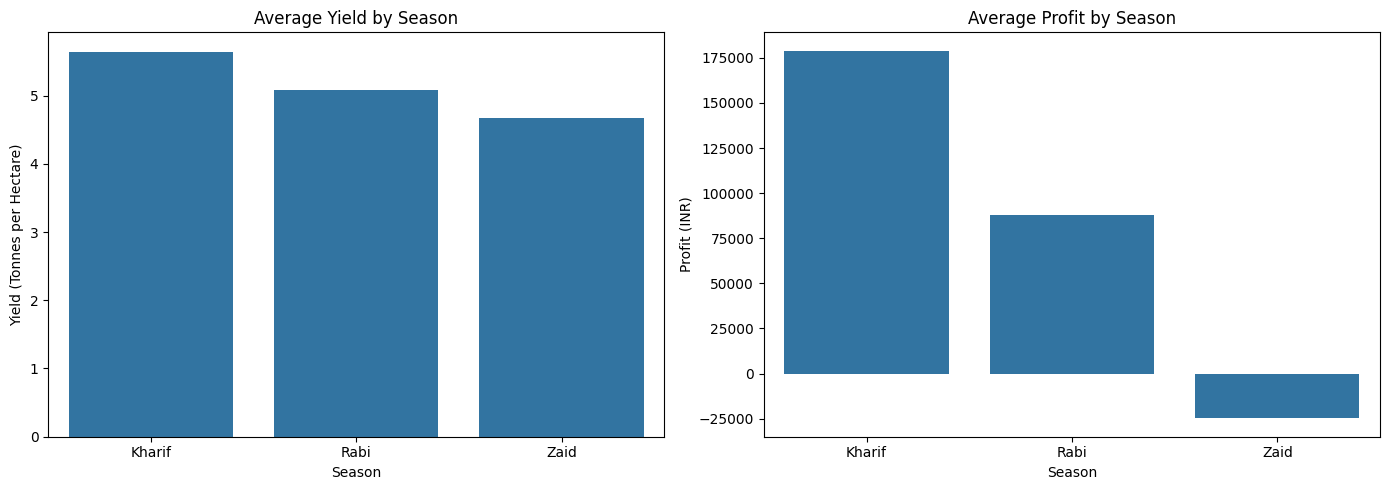

In [22]:
season_performance = df.groupby("Season").agg(
    Average_Yield_Tonnes_Ha=("Yield_Tonnes_Ha", "mean"),
    Total_Production_Tonnes=("Production_Tonnes", "sum"),
    Average_Revenue_INR=("Revenue_INR", "mean"),
    Average_Cost_INR=("Total_Cost_INR", "mean"),
    Average_Profit_INR=("Profit_INR", "mean")
).round(2)

print("Agricultural performance by season:")
display(season_performance)

# Identify best and lowest seasons
best_yield_season = season_performance["Average_Yield_Tonnes_Ha"].idxmax()
lowest_yield_season = season_performance["Average_Yield_Tonnes_Ha"].idxmin()

best_profit_season = season_performance["Average_Profit_INR"].idxmax()
lowest_profit_season = season_performance["Average_Profit_INR"].idxmin()

print(f"\nAnswer:")
print(f"- {best_yield_season} has the highest average yield.")
print(f"- {lowest_yield_season} has the lowest average yield.")
print(f"- {best_profit_season} has the highest average profit.")
print(f"- {lowest_profit_season} has the lowest average profit.")


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=df, x="Season", y="Yield_Tonnes_Ha",
    estimator="mean", errorbar=None, ax=axes[0]
)
axes[0].set_title("Average Yield by Season")
axes[0].set_ylabel("Yield (Tonnes per Hectare)")

sns.barplot(
    data=df, x="Season", y="Profit_INR",
    estimator="mean", errorbar=None, ax=axes[1]
)
axes[1].set_title("Average Profit by Season")
axes[1].set_ylabel("Profit (INR)")

plt.tight_layout()
plt.show()

# 2) What major seasonal patterns can be observed?

Major seasonal patterns:


,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_Moisture_pct,Yield_Tonnes_Ha,Production_Tonnes,Water_Used_m3,Fertilizer_kg_ha,Disease_Pest_Risk_pct,Profit_INR
Season,,,,,,,,,,,
Kharif,852.08,28.45,71.81,6.79,31.20,5.64,46.31,6102.20,187.08,54.47,178914.65
Rabi,436.00,23.49,57.89,7.59,24.05,5.08,41.49,5846.99,185.41,40.48,87689.47
Zaid,299.42,31.04,52.01,8.18,19.17,4.67,38.89,6419.89,184.64,38.22,-24804.82



Seasonal pattern summary:


,Highest_Season,Highest_Value,Lowest_Season,Lowest_Value
Rainfall_mm,Kharif,852.08,Zaid,299.42
Avg_Temperature_C,Zaid,31.04,Rabi,23.49
Humidity_pct,Kharif,71.81,Zaid,52.01
Sunlight_Hours_Day,Zaid,8.18,Kharif,6.79
Soil_Moisture_pct,Kharif,31.20,Zaid,19.17
Yield_Tonnes_Ha,Kharif,5.64,Zaid,4.67
Production_Tonnes,Kharif,46.31,Zaid,38.89
Water_Used_m3,Zaid,6419.89,Rabi,5846.99
Fertilizer_kg_ha,Kharif,187.08,Zaid,184.64
Disease_Pest_Risk_pct,Kharif,54.47,Zaid,38.22


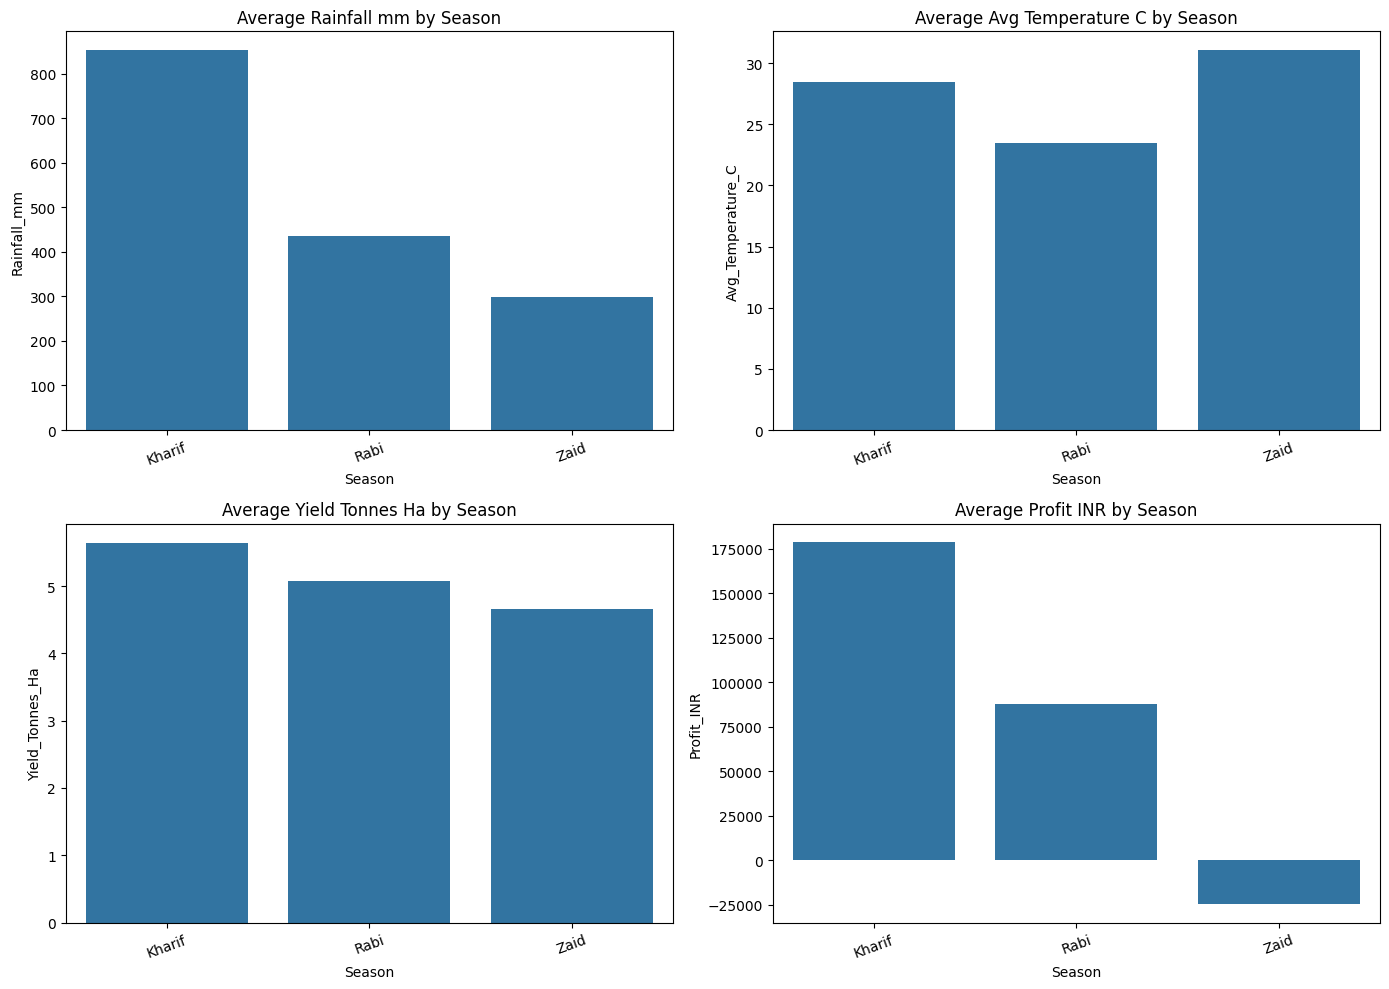


Answer:
- Rainfall mm is highest in Kharif (852.08) and lowest in Zaid (299.42).
- Avg Temperature C is highest in Zaid (31.04) and lowest in Rabi (23.49).
- Humidity pct is highest in Kharif (71.81) and lowest in Zaid (52.01).
- Sunlight Hours Day is highest in Zaid (8.18) and lowest in Kharif (6.79).
- Soil Moisture pct is highest in Kharif (31.20) and lowest in Zaid (19.17).
- Yield Tonnes Ha is highest in Kharif (5.64) and lowest in Zaid (4.67).
- Production Tonnes is highest in Kharif (46.31) and lowest in Zaid (38.89).
- Water Used m3 is highest in Zaid (6,419.89) and lowest in Rabi (5,846.99).
- Fertilizer kg ha is highest in Kharif (187.08) and lowest in Zaid (184.64).
- Disease Pest Risk pct is highest in Kharif (54.47) and lowest in Zaid (38.22).
- Profit INR is highest in Kharif (178,914.65) and lowest in Zaid (-24,804.82).


In [23]:
seasonal_columns = [
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Humidity_pct",
    "Sunlight_Hours_Day",
    "Soil_Moisture_pct",
    "Yield_Tonnes_Ha",
    "Production_Tonnes",
    "Water_Used_m3",
    "Fertilizer_kg_ha",
    "Disease_Pest_Risk_pct",
    "Profit_INR"
]


seasonal_patterns = df.groupby("Season")[seasonal_columns].mean().round(2)

print("Major seasonal patterns:")
display(seasonal_patterns)

pattern_summary = pd.DataFrame({
    "Highest_Season": seasonal_patterns.idxmax(),
    "Highest_Value": seasonal_patterns.max(),
    "Lowest_Season": seasonal_patterns.idxmin(),
    "Lowest_Value": seasonal_patterns.min()
}).round(2)

print("\nSeasonal pattern summary:")
display(pattern_summary)

plot_columns = [
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Yield_Tonnes_Ha",
    "Profit_INR"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, column in zip(axes, plot_columns):
    sns.barplot(
        data=df,
        x="Season",
        y=column,
        estimator="mean",
        errorbar=None,
        ax=ax
    )
    ax.set_title(f"Average {column.replace('_', ' ')} by Season")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

print("\nAnswer:")
for column in seasonal_columns:
    highest = seasonal_patterns[column].idxmax()
    lowest = seasonal_patterns[column].idxmin()

    print(
        f"- {column.replace('_', ' ')} is highest in {highest} "
        f"({seasonal_patterns.loc[highest, column]:,.2f}) "
        f"and lowest in {lowest} "
        f"({seasonal_patterns.loc[lowest, column]:,.2f})."
    )

# 3) Which characteristics change between seasons?

Average characteristics by season:


,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,Fertilizer_kg_ha,Pesticide_Litre_ha,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
Season,,,,,,,,,,,,,,
Kharif,852.08,28.45,71.81,6.79,6.73,31.20,120.02,58.10,105.30,187.08,5.08,6102.20,5.89,54.47
Rabi,436.00,23.49,57.89,7.59,6.67,24.05,120.40,57.31,103.93,185.41,5.02,5846.99,5.19,40.48
Zaid,299.42,31.04,52.01,8.18,6.69,19.17,120.53,58.13,105.42,184.64,5.17,6419.89,4.41,38.22



Characteristics that change between seasons:


,Minimum_Value,Maximum_Value,Difference,Lowest_Season,Highest_Season,Percentage_Change
Rainfall_mm,299.42,852.08,552.66,Zaid,Kharif,104.44
Soil_Moisture_pct,19.17,31.20,12.03,Zaid,Kharif,48.50
Disease_Pest_Risk_pct,38.22,54.47,16.25,Zaid,Kharif,36.61
Humidity_pct,52.01,71.81,19.80,Zaid,Kharif,32.69
Water_Efficiency_t_per_1000m3,4.41,5.89,1.48,Zaid,Kharif,28.66
Avg_Temperature_C,23.49,31.04,7.55,Rabi,Zaid,27.30
Sunlight_Hours_Day,6.79,8.18,1.39,Kharif,Zaid,18.48
Water_Used_m3,5846.99,6419.89,572.90,Rabi,Zaid,9.36
Pesticide_Litre_ha,5.02,5.17,0.15,Rabi,Zaid,2.95
Potassium_kg_ha,103.93,105.42,1.49,Rabi,Zaid,1.42


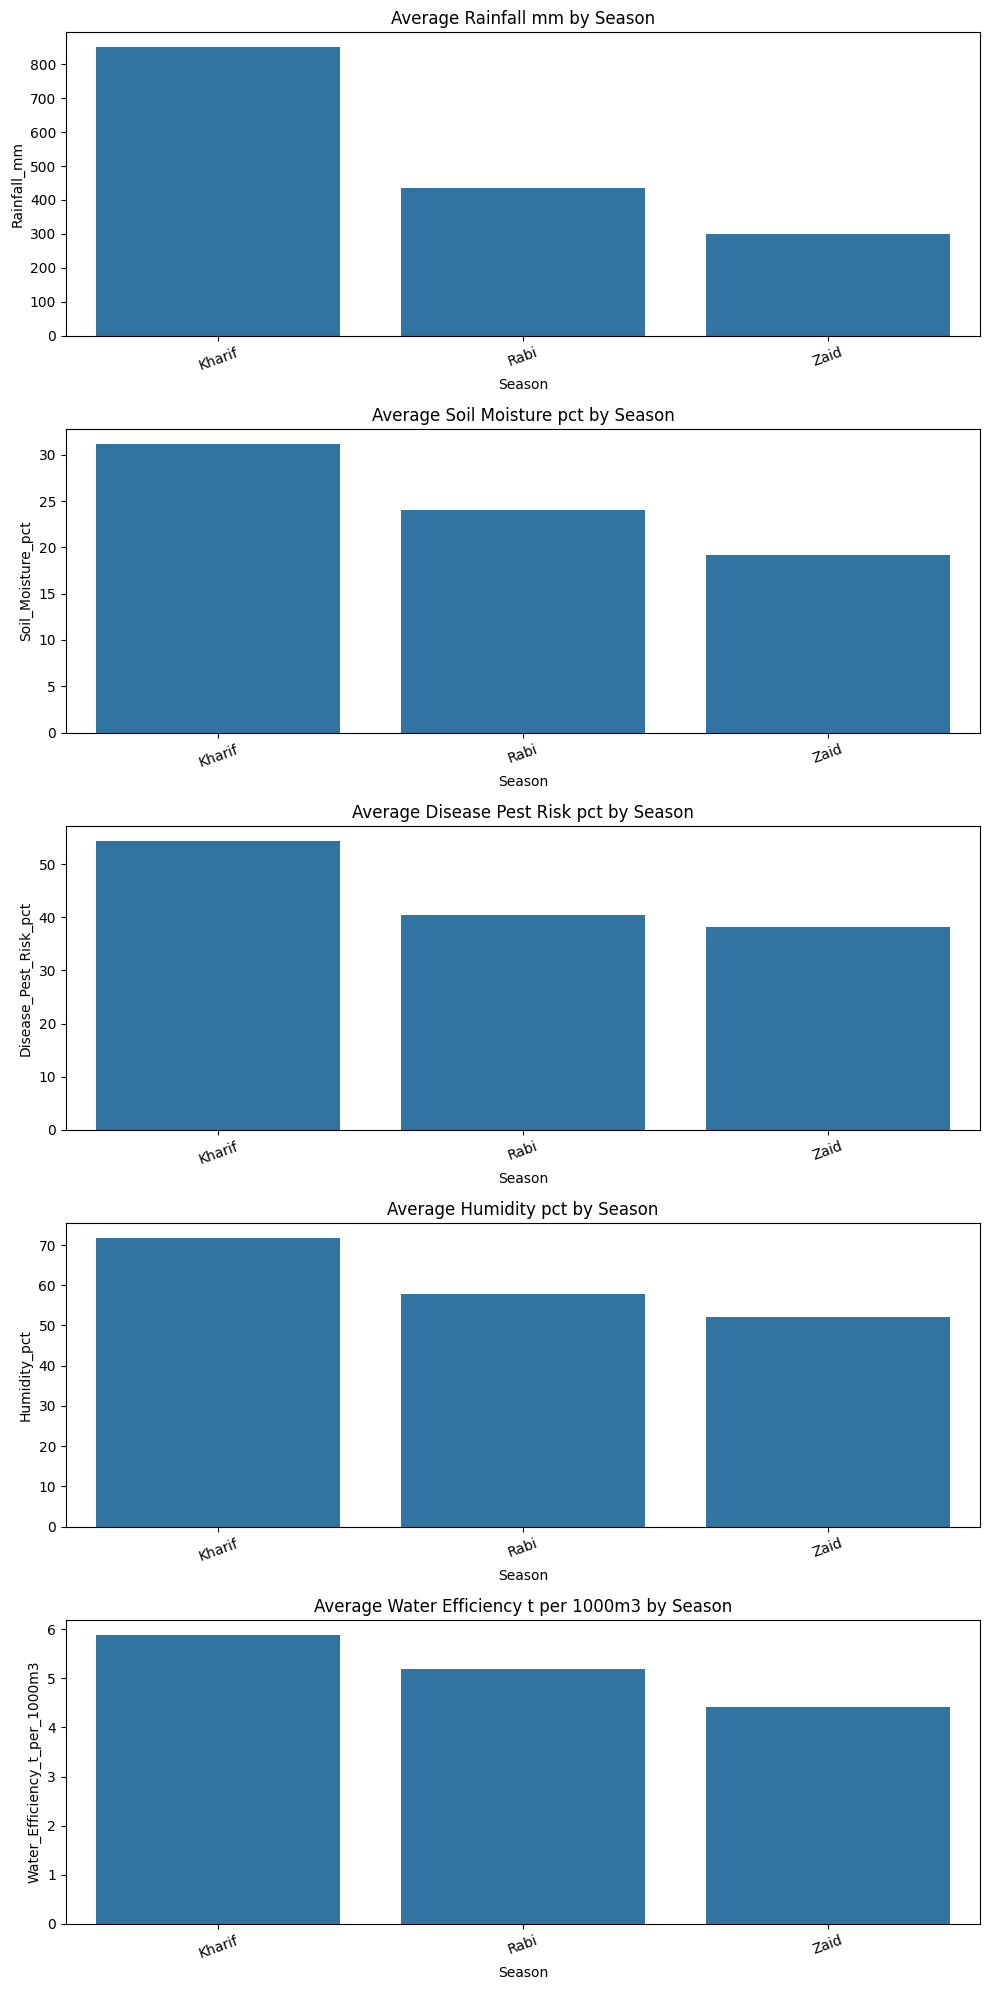


Answer:
- Rainfall mm changes the most across seasons. It is highest in Kharif (852.08) and lowest in Zaid (299.42).
- Soil Moisture pct changes the most across seasons. It is highest in Kharif (31.20) and lowest in Zaid (19.17).
- Disease Pest Risk pct changes the most across seasons. It is highest in Kharif (54.47) and lowest in Zaid (38.22).
- Humidity pct changes the most across seasons. It is highest in Kharif (71.81) and lowest in Zaid (52.01).
- Water Efficiency t per 1000m3 changes the most across seasons. It is highest in Kharif (5.89) and lowest in Zaid (4.41).


In [24]:
characteristics = [
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Humidity_pct",
    "Sunlight_Hours_Day",
    "Soil_pH",
    "Soil_Moisture_pct",
    "Nitrogen_kg_ha",
    "Phosphorus_kg_ha",
    "Potassium_kg_ha",
    "Fertilizer_kg_ha",
    "Pesticide_Litre_ha",
    "Water_Used_m3",
    "Water_Efficiency_t_per_1000m3",
    "Disease_Pest_Risk_pct"
]

characteristics = [col for col in characteristics if col in df.columns]

seasonal_characteristics = df.groupby("Season")[characteristics].mean().round(2)

print("Average characteristics by season:")
display(seasonal_characteristics)

change_summary = pd.DataFrame({
    "Minimum_Value": seasonal_characteristics.min(),
    "Maximum_Value": seasonal_characteristics.max(),
    "Difference": seasonal_characteristics.max() - seasonal_characteristics.min(),
    "Lowest_Season": seasonal_characteristics.idxmin(),
    "Highest_Season": seasonal_characteristics.idxmax()
})

change_summary["Percentage_Change"] = (
    change_summary["Difference"]
    / seasonal_characteristics.mean().replace(0, pd.NA)
    * 100
)

change_summary = change_summary.sort_values(
    "Percentage_Change",
    ascending=False
).round(2)

print("\nCharacteristics that change between seasons:")
display(change_summary)

top_characteristics = change_summary.head(5).index

fig, axes = plt.subplots(len(top_characteristics), 1, figsize=(10, 4 * len(top_characteristics)))

if len(top_characteristics) == 1:
    axes = [axes]

for ax, column in zip(axes, top_characteristics):
    sns.barplot(
        data=df,
        x="Season",
        y=column,
        estimator="mean",
        errorbar=None,
        ax=ax
    )
    ax.set_title(f"Average {column.replace('_', ' ')} by Season")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

print("\nAnswer:")
for characteristic, row in change_summary.head(5).iterrows():
    print(
        f"- {characteristic.replace('_', ' ')} changes the most across seasons. "
        f"It is highest in {row['Highest_Season']} "
        f"({row['Maximum_Value']:,.2f}) and lowest in {row['Lowest_Season']} "
        f"({row['Minimum_Value']:,.2f})."
    )

# 4) What differences exist between agricultural activities in different seasons?

Crop distribution by season (%):


Crop,Chilli,Cotton,Groundnut,Maize,Pulses,Rice,Sugarcane,Wheat
Season,,,,,,,,
Kharif,10.40,12.09,10.85,13.15,12.42,17.65,7.03,16.41
Rabi,10.02,12.35,10.88,14.32,13.09,16.84,7.93,14.57
Zaid,10.77,15.49,9.09,14.14,10.44,17.17,8.59,14.31


Irrigation method distribution by season (%):


Irrigation_Method,Drip,Flood,Rainfed,Sprinkler
Season,,,,
Kharif,22.77,33.16,26.03,18.04
Rabi,22.74,32.33,26.92,18.01
Zaid,23.57,32.66,23.57,20.20


Average farming activities and outcomes by season:


,Farm_Area_Hectares,Fertilizer_kg_ha,Pesticide_Litre_ha,Water_Used_m3,Yield_Tonnes_Ha,Production_Tonnes
Season,,,,,,
Kharif,7.94,187.08,5.08,6102.20,5.64,46.31
Rabi,7.75,185.41,5.02,5846.99,5.08,41.49
Zaid,8.09,184.64,5.17,6419.89,4.67,38.89


Main agricultural activities by season:


,Most_Common_Crop,Most_Common_Irrigation_Method
Season,,
Kharif,Rice,Flood
Rabi,Rice,Flood
Zaid,Rice,Flood


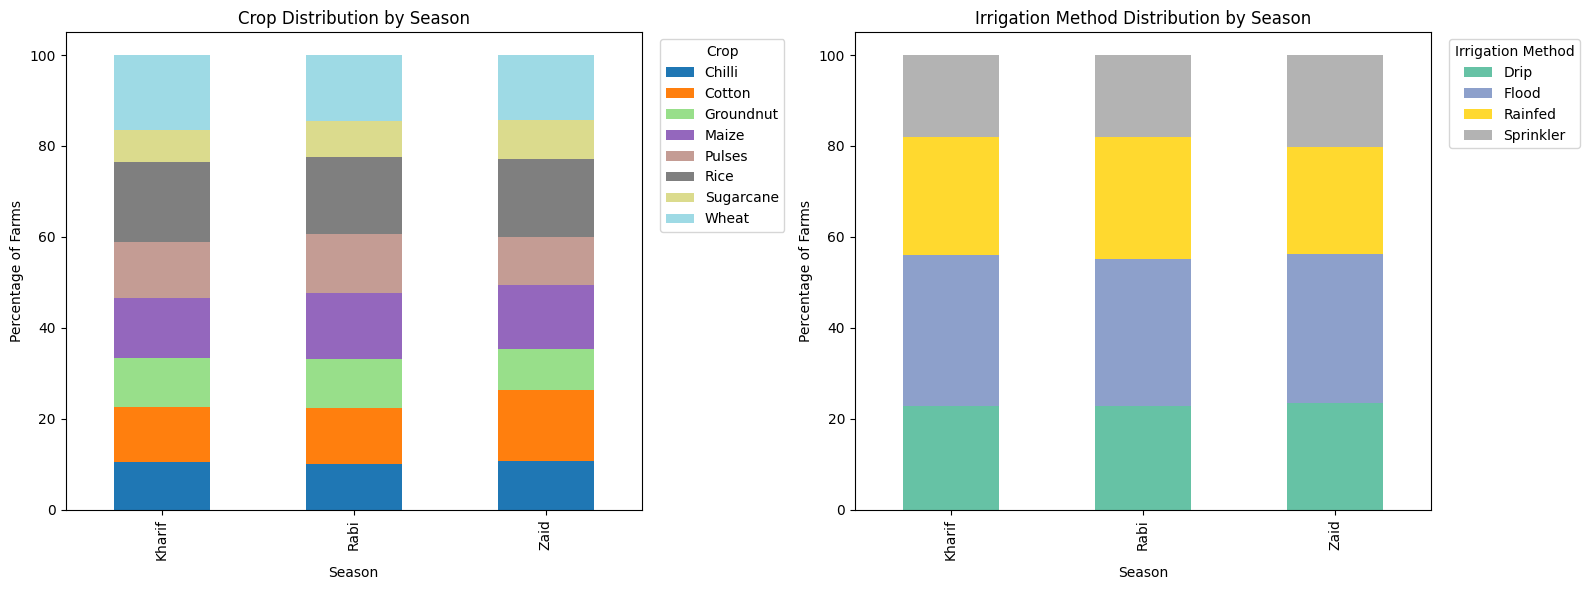


Answer:
- In Kharif, the most common crop is Rice and the most common irrigation method is Flood.
- In Rabi, the most common crop is Rice and the most common irrigation method is Flood.
- In Zaid, the most common crop is Rice and the most common irrigation method is Flood.


In [25]:
crop_by_season = pd.crosstab(
    df["Season"],
    df["Crop"],
    normalize="index"
) * 100

print("Crop distribution by season (%):")
display(crop_by_season.round(2))

# 2. Compare irrigation methods across seasons
irrigation_by_season = pd.crosstab(
    df["Season"],
    df["Irrigation_Method"],
    normalize="index"
) * 100

print("Irrigation method distribution by season (%):")
display(irrigation_by_season.round(2))

activity_columns = [
    "Farm_Area_Hectares",
    "Fertilizer_kg_ha",
    "Pesticide_Litre_ha",
    "Water_Used_m3",
    "Yield_Tonnes_Ha",
    "Production_Tonnes"
]

seasonal_activities = df.groupby("Season")[activity_columns].mean().round(2)

print("Average farming activities and outcomes by season:")
display(seasonal_activities)

most_common_crop = df.groupby("Season")["Crop"].agg(
    lambda x: x.value_counts().idxmax()
)

most_common_irrigation = df.groupby("Season")["Irrigation_Method"].agg(
    lambda x: x.value_counts().idxmax()
)

activity_summary = pd.DataFrame({
    "Most_Common_Crop": most_common_crop,
    "Most_Common_Irrigation_Method": most_common_irrigation
})

print("Main agricultural activities by season:")
display(activity_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

crop_by_season.plot(
    kind="bar",
    stacked=True,
    ax=axes[0],
    colormap="tab20"
)
axes[0].set_title("Crop Distribution by Season")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Percentage of Farms")
axes[0].legend(title="Crop", bbox_to_anchor=(1.02, 1), loc="upper left")

irrigation_by_season.plot(
    kind="bar",
    stacked=True,
    ax=axes[1],
    colormap="Set2"
)
axes[1].set_title("Irrigation Method Distribution by Season")
axes[1].set_xlabel("Season")
axes[1].set_ylabel("Percentage of Farms")
axes[1].legend(
    title="Irrigation Method",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

print("\nAnswer:")
for season in activity_summary.index:
    print(
        f"- In {season}, the most common crop is "
        f"{activity_summary.loc[season, 'Most_Common_Crop']} and the most "
        f"common irrigation method is "
        f"{activity_summary.loc[season, 'Most_Common_Irrigation_Method']}."
    )

# 5) Are there noticeable variations in resource usage across seasons?

Average resource usage by season:


,Water_Used_m3,Water_Efficiency_t_per_1000m3,Fertilizer_kg_ha,Pesticide_Litre_ha,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha
Season,,,,,,,
Kharif,6102.20,5.89,187.08,5.08,120.02,58.10,105.30
Rabi,5846.99,5.19,185.41,5.02,120.40,57.31,103.93
Zaid,6419.89,4.41,184.64,5.17,120.53,58.13,105.42



Resource variation summary:


,Lowest_Season,Lowest_Value,Highest_Season,Highest_Value,Difference,Percentage_Variation
Water_Efficiency_t_per_1000m3,Zaid,4.41,Kharif,5.89,1.48,28.66
Water_Used_m3,Rabi,5846.99,Zaid,6419.89,572.90,9.36
Pesticide_Litre_ha,Rabi,5.02,Zaid,5.17,0.15,2.95
Potassium_kg_ha,Rabi,103.93,Zaid,105.42,1.49,1.42
Phosphorus_kg_ha,Rabi,57.31,Zaid,58.13,0.82,1.42
Fertilizer_kg_ha,Zaid,184.64,Kharif,187.08,2.44,1.31
Nitrogen_kg_ha,Kharif,120.02,Zaid,120.53,0.51,0.42


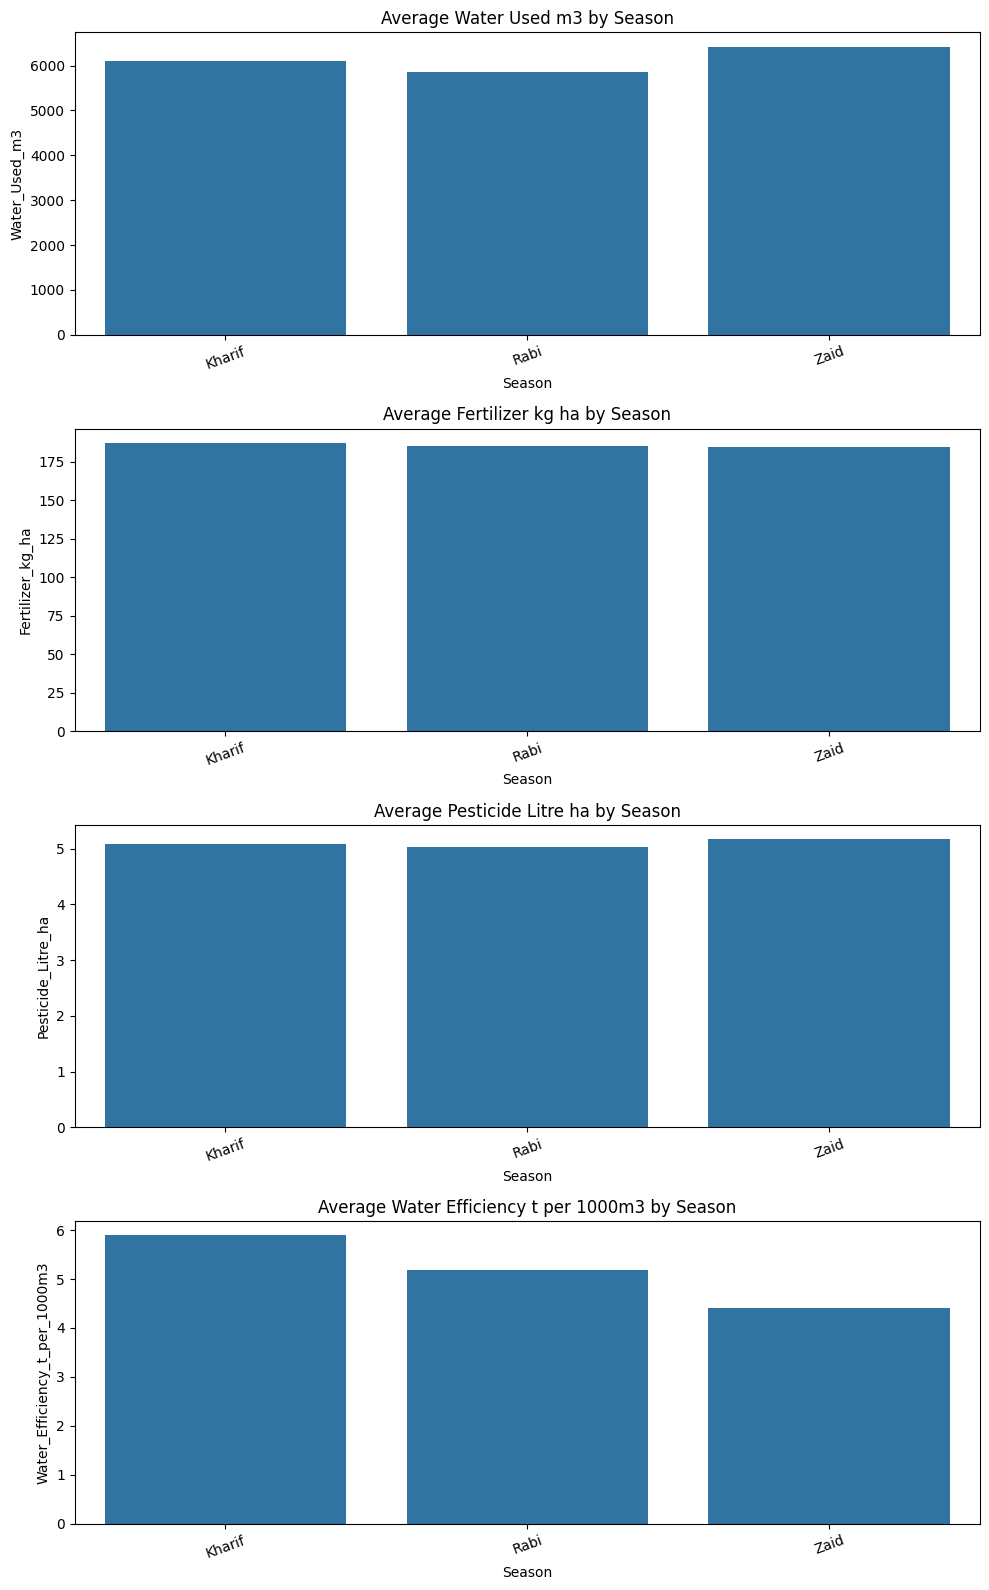


Answer:
- Water Efficiency t per 1000m3 is highest in Kharif (5.89) and lowest in Zaid (4.41). The seasonal variation is 28.66%.
- Water Used m3 is highest in Zaid (6,419.89) and lowest in Rabi (5,846.99). The seasonal variation is 9.36%.
- Pesticide Litre ha is highest in Zaid (5.17) and lowest in Rabi (5.02). The seasonal variation is 2.95%.
- Potassium kg ha is highest in Zaid (105.42) and lowest in Rabi (103.93). The seasonal variation is 1.42%.
- Phosphorus kg ha is highest in Zaid (58.13) and lowest in Rabi (57.31). The seasonal variation is 1.42%.
- Fertilizer kg ha is highest in Kharif (187.08) and lowest in Zaid (184.64). The seasonal variation is 1.31%.
- Nitrogen kg ha is highest in Zaid (120.53) and lowest in Kharif (120.02). The seasonal variation is 0.42%.


In [26]:
resource_columns = [
    "Water_Used_m3",
    "Water_Efficiency_t_per_1000m3",
    "Fertilizer_kg_ha",
    "Pesticide_Litre_ha",
    "Nitrogen_kg_ha",
    "Phosphorus_kg_ha",
    "Potassium_kg_ha"
]

resource_columns = [col for col in resource_columns if col in df.columns]


seasonal_resource_use = (
    df.groupby("Season")[resource_columns]
    .mean()
    .round(2)
)

print("Average resource usage by season:")
display(seasonal_resource_use)

resource_summary = pd.DataFrame({
    "Lowest_Season": seasonal_resource_use.idxmin(),
    "Lowest_Value": seasonal_resource_use.min(),
    "Highest_Season": seasonal_resource_use.idxmax(),
    "Highest_Value": seasonal_resource_use.max(),
})

resource_summary["Difference"] = (
    resource_summary["Highest_Value"] -
    resource_summary["Lowest_Value"]
)

resource_summary["Percentage_Variation"] = (
    resource_summary["Difference"] /
    seasonal_resource_use.mean().replace(0, pd.NA) * 100
)

resource_summary = resource_summary.sort_values(
    "Percentage_Variation",
    ascending=False
).round(2)

print("\nResource variation summary:")
display(resource_summary)

plot_columns = [
    "Water_Used_m3",
    "Fertilizer_kg_ha",
    "Pesticide_Litre_ha",
    "Water_Efficiency_t_per_1000m3"
]

plot_columns = [col for col in plot_columns if col in df.columns]

fig, axes = plt.subplots(
    len(plot_columns),
    1,
    figsize=(10, 4 * len(plot_columns))
)

if len(plot_columns) == 1:
    axes = [axes]

for ax, column in zip(axes, plot_columns):
    sns.barplot(
        data=df,
        x="Season",
        y=column,
        estimator="mean",
        errorbar=None,
        ax=ax
    )
    ax.set_title(f"Average {column.replace('_', ' ')} by Season")
    ax.set_xlabel("Season")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

# Automatic answer
print("\nAnswer:")
for resource, row in resource_summary.iterrows():
    print(
        f"- {resource.replace('_', ' ')} is highest in "
        f"{row['Highest_Season']} ({row['Highest_Value']:,.2f}) "
        f"and lowest in {row['Lowest_Season']} "
        f"({row['Lowest_Value']:,.2f}). "
        f"The seasonal variation is {row['Percentage_Variation']:,.2f}%."
    )

# 6) Are there relationships between seasonal environmental conditions and agricultural performance?

Seasonal environmental conditions and agricultural performance:


,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Disease_Pest_Risk_pct,Yield_Tonnes_Ha,Production_Tonnes,Revenue_INR,Profit_INR
Season,,,,,,,,,,,
Kharif,852.08,28.45,71.81,6.79,6.73,31.20,54.47,5.64,46.31,710719.06,178914.65
Rabi,436.00,23.49,57.89,7.59,6.67,24.05,40.48,5.08,41.49,601526.05,87689.47
Zaid,299.42,31.04,52.01,8.18,6.69,19.17,38.22,4.67,38.89,519171.90,-24804.82


Correlation between environmental conditions and performance:


,Yield_Tonnes_Ha,Production_Tonnes,Revenue_INR,Profit_INR
Rainfall_mm,0.031,0.025,0.099,0.108
Avg_Temperature_C,0.009,0.007,0.027,0.009
Humidity_pct,0.011,0.004,0.057,0.064
Sunlight_Hours_Day,-0.015,-0.024,-0.047,-0.055
Soil_pH,-0.021,-0.013,-0.009,-0.013
Soil_Moisture_pct,0.010,0.005,0.080,0.092
Disease_Pest_Risk_pct,0.013,0.014,0.061,0.068


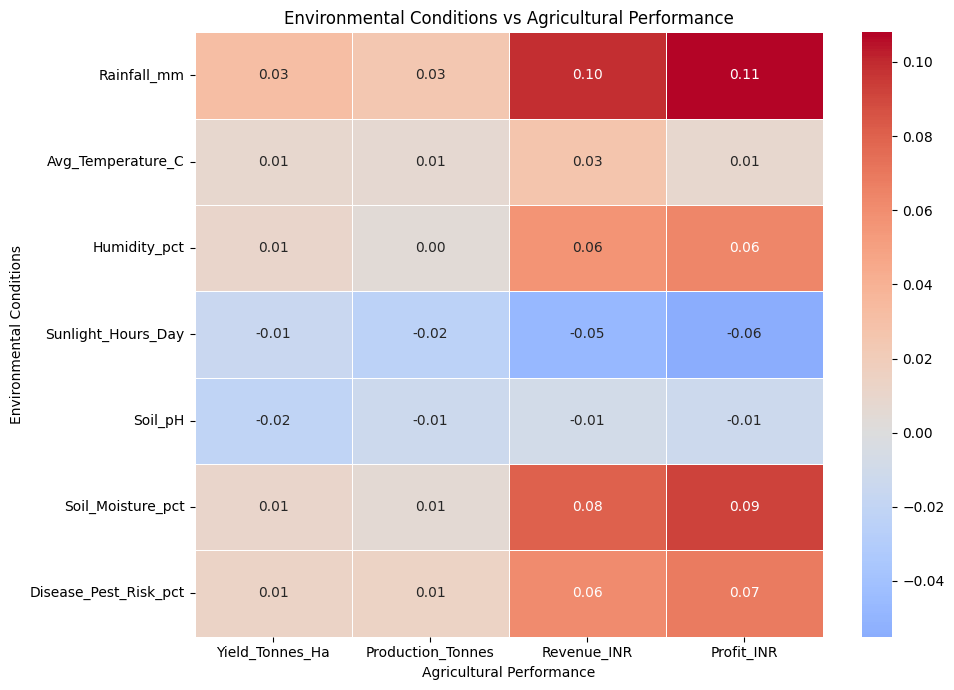

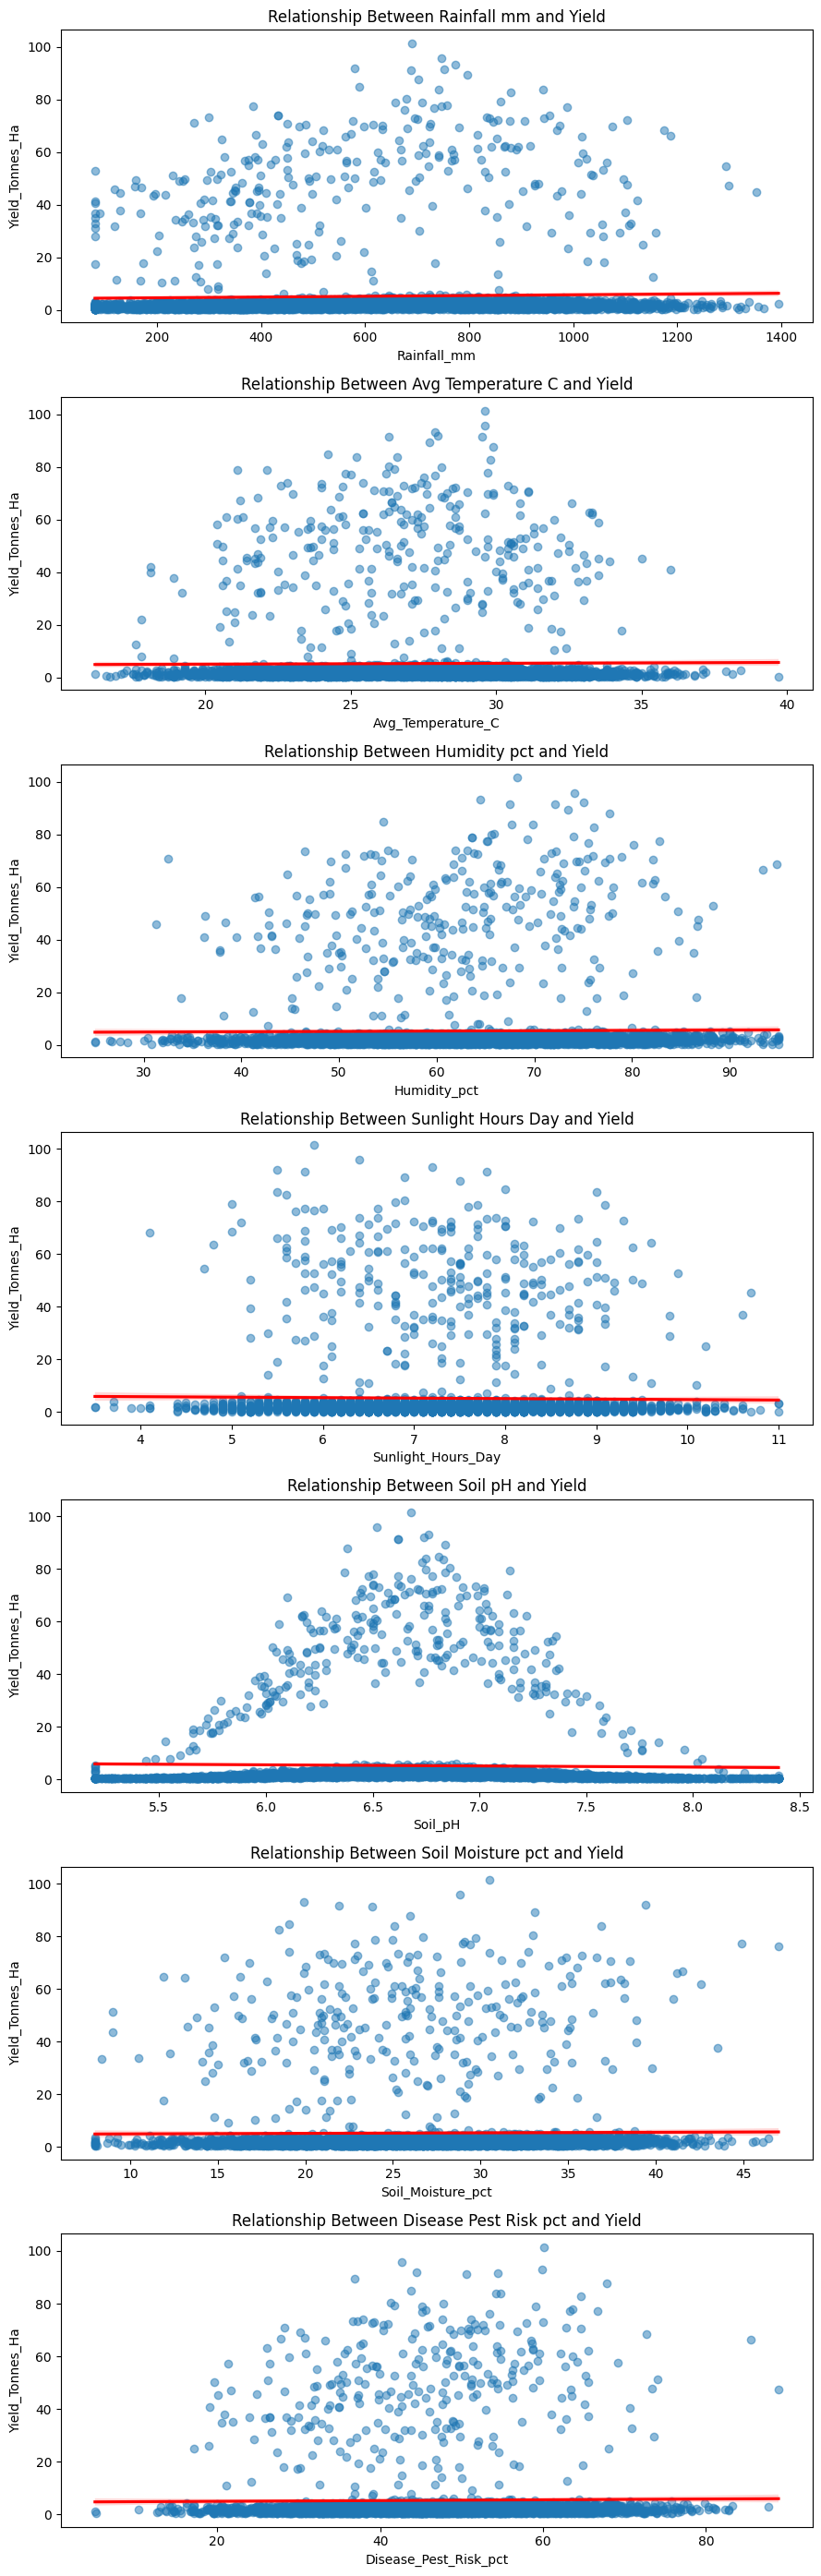


Answer:

For Yield Tonnes Ha:
- Strongest positive relationship: Rainfall mm (correlation = 0.031)
- Strongest negative relationship: Soil pH (correlation = -0.021)

For Production Tonnes:
- Strongest positive relationship: Rainfall mm (correlation = 0.025)
- Strongest negative relationship: Sunlight Hours Day (correlation = -0.024)

For Revenue INR:
- Strongest positive relationship: Rainfall mm (correlation = 0.099)
- Strongest negative relationship: Sunlight Hours Day (correlation = -0.047)

For Profit INR:
- Strongest positive relationship: Rainfall mm (correlation = 0.108)
- Strongest negative relationship: Sunlight Hours Day (correlation = -0.055)

Note: Correlation shows association, not proof that an environmental condition directly causes a change in performance.


In [27]:
environment_columns = [
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Humidity_pct",
    "Sunlight_Hours_Day",
    "Soil_pH",
    "Soil_Moisture_pct",
    "Disease_Pest_Risk_pct"
]

performance_columns = [
    "Yield_Tonnes_Ha",
    "Production_Tonnes",
    "Revenue_INR",
    "Profit_INR"
]

# Keep only columns present in the dataset
environment_columns = [
    col for col in environment_columns if col in df.columns
]
performance_columns = [
    col for col in performance_columns if col in df.columns
]

# 1. Average environmental conditions and performance by season
seasonal_environment_performance = (
    df.groupby("Season")[environment_columns + performance_columns]
    .mean()
    .round(2)
)

print("Seasonal environmental conditions and agricultural performance:")
display(seasonal_environment_performance)

# 2. Calculate correlations
correlation_matrix = df[
    environment_columns + performance_columns
].corr(numeric_only=True)

environment_performance_corr = correlation_matrix.loc[
    environment_columns,
    performance_columns
].round(3)

print("Correlation between environmental conditions and performance:")
display(environment_performance_corr)

# 3. Correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    environment_performance_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Environmental Conditions vs Agricultural Performance")
plt.xlabel("Agricultural Performance")
plt.ylabel("Environmental Conditions")
plt.tight_layout()
plt.show()

# 4. Scatter plots for environmental conditions versus yield
if "Yield_Tonnes_Ha" in df.columns:
    fig, axes = plt.subplots(
        len(environment_columns),
        1,
        figsize=(9, 4 * len(environment_columns))
    )

    if len(environment_columns) == 1:
        axes = [axes]

    for ax, column in zip(axes, environment_columns):
        sns.regplot(
            data=df,
            x=column,
            y="Yield_Tonnes_Ha",
            scatter_kws={"alpha": 0.5},
            line_kws={"color": "red"},
            ax=ax
        )
        ax.set_title(
            f"Relationship Between {column.replace('_', ' ')} "
            f"and Yield"
        )

    plt.tight_layout()
    plt.show()

# 5. Automatic written answer for each performance indicator
print("\nAnswer:")

for performance in performance_columns:
    correlations = environment_performance_corr[performance].dropna()

    strongest_positive = correlations.idxmax()
    strongest_negative = correlations.idxmin()

    positive_value = correlations[strongest_positive]
    negative_value = correlations[strongest_negative]

    print(
        f"\nFor {performance.replace('_', ' ')}:"
    )
    print(
        f"- Strongest positive relationship: "
        f"{strongest_positive.replace('_', ' ')} "
        f"(correlation = {positive_value:.3f})"
    )
    print(
        f"- Strongest negative relationship: "
        f"{strongest_negative.replace('_', ' ')} "
        f"(correlation = {negative_value:.3f})"
    )

print(
    "\nNote: Correlation shows association, not proof that an "
    "environmental condition directly causes a change in performance."
)

# 7) How do economic outcomes vary across seasons?

Average economic outcomes by season:


,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR
Season,,,,
Kharif,44850.91,531804.41,710719.06,178914.65
Rabi,44747.97,513836.58,601526.05,87689.47
Zaid,44212.03,543976.73,519171.90,-24804.82



Total economic outcomes by season:


,Total_Cost_INR,Revenue_INR,Profit_INR
Season,,,
Kharif,946080042,1264369200,318289158
Rabi,836012113,978682881,142670768
Zaid,323122177,308388111,-14734066



Economic comparison summary:


,Highest_Season,Highest_Value,Lowest_Season,Lowest_Value
Market_Price_INR_Tonne,Kharif,44850.91,Zaid,44212.03
Total_Cost_INR,Zaid,543976.73,Rabi,513836.58
Revenue_INR,Kharif,710719.06,Zaid,519171.90
Profit_INR,Kharif,178914.65,Zaid,-24804.82


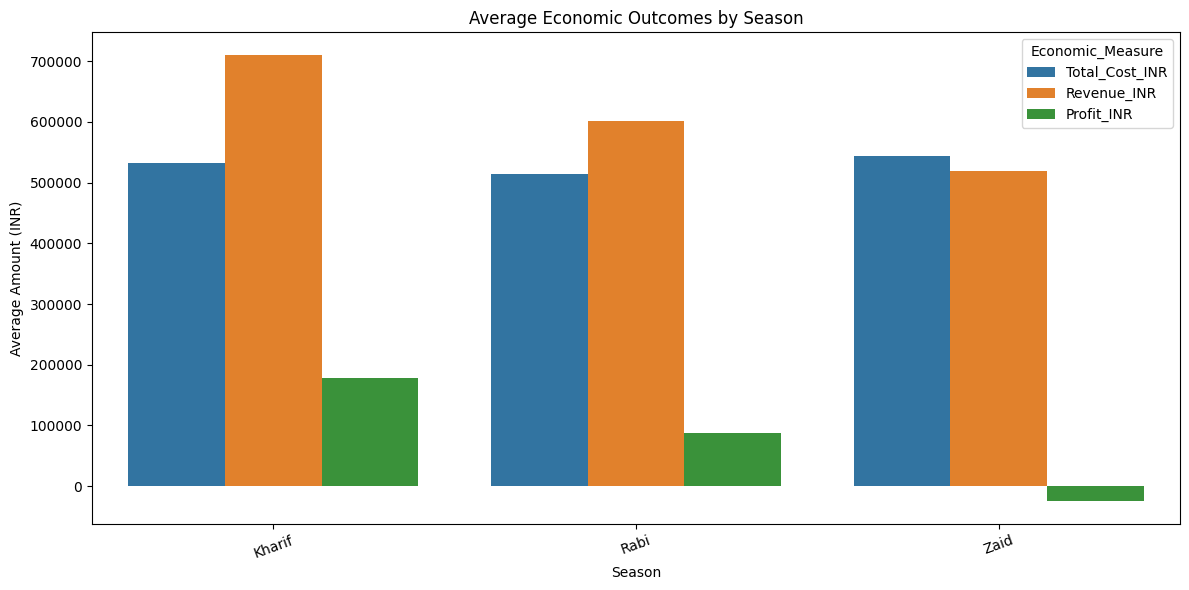


Answer:
- The highest average revenue occurs in Kharif: INR 710,719.06.
- The highest average profit occurs in Kharif: INR 178,914.65.
- The lowest average profit occurs in Zaid: INR -24,804.82.
- The highest average production cost occurs in Zaid: INR 543,976.73.


In [28]:
economic_columns = [
    "Market_Price_INR_Tonne",
    "Total_Cost_INR",
    "Revenue_INR",
    "Profit_INR"
]

economic_columns = [
    column for column in economic_columns
    if column in df.columns
]

seasonal_economics = (
    df.groupby("Season")[economic_columns]
    .mean()
    .round(2)
)

print("Average economic outcomes by season:")
display(seasonal_economics)

economic_totals = (
    df.groupby("Season")[["Total_Cost_INR", "Revenue_INR", "Profit_INR"]]
    .sum()
    .round(2)
)

print("\nTotal economic outcomes by season:")
display(economic_totals)

economic_summary = pd.DataFrame({
    "Highest_Season": seasonal_economics.idxmax(),
    "Highest_Value": seasonal_economics.max(),
    "Lowest_Season": seasonal_economics.idxmin(),
    "Lowest_Value": seasonal_economics.min()
}).round(2)

print("\nEconomic comparison summary:")
display(economic_summary)

plot_columns = ["Total_Cost_INR", "Revenue_INR", "Profit_INR"]
plot_columns = [column for column in plot_columns if column in df.columns]

melted_economics = seasonal_economics[plot_columns].reset_index().melt(
    id_vars="Season",
    var_name="Economic_Measure",
    value_name="Average_INR"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=melted_economics,
    x="Season",
    y="Average_INR",
    hue="Economic_Measure"
)

plt.title("Average Economic Outcomes by Season")
plt.xlabel("Season")
plt.ylabel("Average Amount (INR)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

best_profit_season = seasonal_economics["Profit_INR"].idxmax()
lowest_profit_season = seasonal_economics["Profit_INR"].idxmin()
best_revenue_season = seasonal_economics["Revenue_INR"].idxmax()
highest_cost_season = seasonal_economics["Total_Cost_INR"].idxmax()

print("\nAnswer:")
print(
    f"- The highest average revenue occurs in {best_revenue_season}: "
    f"INR {seasonal_economics.loc[best_revenue_season, 'Revenue_INR']:,.2f}."
)
print(
    f"- The highest average profit occurs in {best_profit_season}: "
    f"INR {seasonal_economics.loc[best_profit_season, 'Profit_INR']:,.2f}."
)
print(
    f"- The lowest average profit occurs in {lowest_profit_season}: "
    f"INR {seasonal_economics.loc[lowest_profit_season, 'Profit_INR']:,.2f}."
)
print(
    f"- The highest average production cost occurs in {highest_cost_season}: "
    f"INR {seasonal_economics.loc[highest_cost_season, 'Total_Cost_INR']:,.2f}."
)

# 8) Are some seasonal patterns consistent across different regions or categories?


Seasonal Yield Pattern by State


Season,Kharif,Rabi,Zaid
State,,,
Andhra Pradesh,5.69,3.49,4.48
Gujarat,6.34,5.52,4.10
Karnataka,6.52,4.61,6.62
Madhya Pradesh,6.00,3.80,5.54
Maharashtra,5.45,5.50,2.29
Punjab,4.10,8.61,5.91
Tamil Nadu,5.52,4.56,4.10
Telangana,5.57,4.83,4.28


Most successful season within each State:


,Number_of_Categories,Percentage_of_Categories
Kharif,5,62.5
Rabi,2,25.0
Zaid,1,12.5


Answer: Kharif is the highest-yield season for 62.50% of State groups.
Conclusion: The seasonal pattern is moderately consistent across State groups.


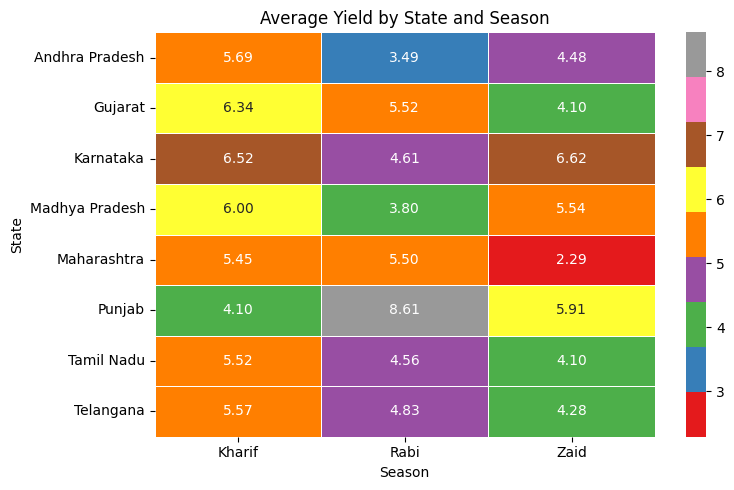


Seasonal Yield Pattern by District


Season,Kharif,Rabi,Zaid
District,,,
Erode,4.33,4.48,3.31
Guntur,6.02,4.58,6.30
Indore,6.12,3.54,4.54
Krishna,5.51,4.76,2.91
Ludhiana,6.41,5.62,5.08
Nalgonda,6.58,4.47,7.51
Nashik,5.55,4.72,3.39
Raichur,4.12,6.74,3.29
Rajkot,6.69,5.96,4.33


Most successful season within each District:


,Number_of_Categories,Percentage_of_Categories
Kharif,5,50.0
Zaid,3,30.0
Rabi,2,20.0


Answer: Kharif is the highest-yield season for 50.00% of District groups.
Conclusion: The seasonal pattern is moderately consistent across District groups.


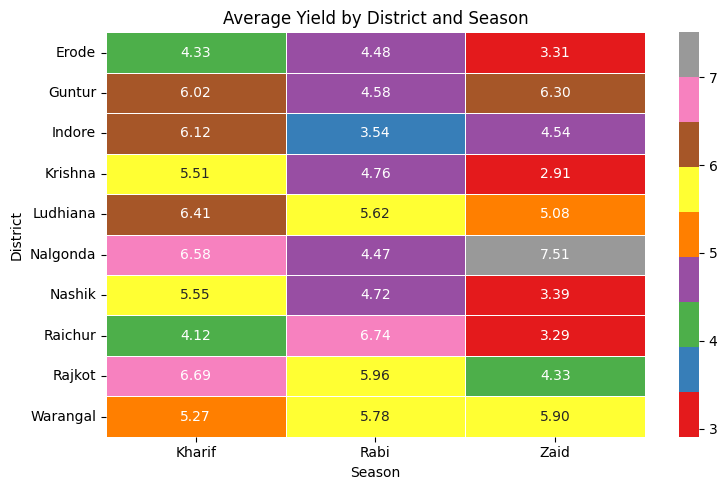


Seasonal Yield Pattern by Crop


Season,Kharif,Rabi,Zaid
Crop,,,
Chilli,1.73,1.46,1.18
Cotton,1.37,1.19,0.95
Groundnut,1.48,1.22,1.04
Maize,2.97,2.61,2.30
Pulses,1.04,0.87,0.65
Rice,2.71,2.33,1.90
Sugarcane,53.46,43.94,38.42
Wheat,2.26,2.06,1.75


Most successful season within each Crop:


,Number_of_Categories,Percentage_of_Categories
Kharif,8,100.0


Answer: Kharif is the highest-yield season for 100.00% of Crop groups.
Conclusion: The seasonal pattern is strongly consistent across Crop groups.


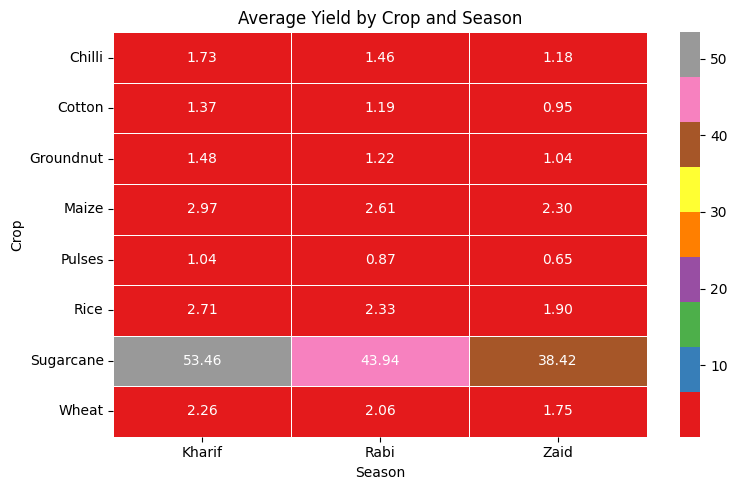


Seasonal Yield Pattern by Irrigation_Method


Season,Kharif,Rabi,Zaid
Irrigation_Method,,,
Drip,7.26,6.21,5.85
Flood,5.00,5.10,4.03
Rainfed,5.72,3.94,3.06
Sprinkler,4.67,5.36,6.17


Most successful season within each Irrigation_Method:


,Number_of_Categories,Percentage_of_Categories
Kharif,2,50.0
Rabi,1,25.0
Zaid,1,25.0


Answer: Kharif is the highest-yield season for 50.00% of Irrigation_Method groups.
Conclusion: The seasonal pattern is moderately consistent across Irrigation_Method groups.


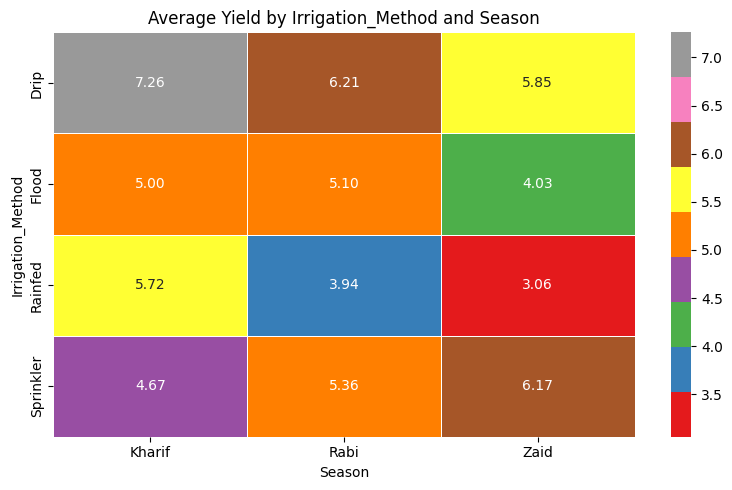

In [30]:
performance_column = "Yield_Tonnes_Ha"


categories = ["State", "District", "Crop", "Irrigation_Method"]


categories = [col for col in categories if col in df.columns]

for category in categories:
    print(f"\n{'=' * 70}")
    print(f"Seasonal Yield Pattern by {category}")
    print(f"{'=' * 70}")

 
    seasonal_pattern = pd.pivot_table(
        df,
        index=category,
        columns="Season",
        values=performance_column,
        aggfunc="mean"
    ).round(2)

    display(seasonal_pattern)

   
    best_season = seasonal_pattern.idxmax(axis=1)

   
    consistency = best_season.value_counts()

    consistency_percent = (
        consistency / consistency.sum() * 100
    ).round(2)

    consistency_table = pd.DataFrame({
        "Number_of_Categories": consistency,
        "Percentage_of_Categories": consistency_percent
    })

    print(f"Most successful season within each {category}:")
    display(consistency_table)

 
    most_common_season = consistency.idxmax()
    consistency_rate = consistency_percent.loc[most_common_season]

    print(
        f"Answer: {most_common_season} is the highest-yield season for "
        f"{consistency_rate:.2f}% of {category} groups."
    )

    if consistency_rate >= 70:
        print(
            "Conclusion: The seasonal pattern is strongly consistent "
            f"across {category} groups."
        )
    elif consistency_rate >= 50:
        print(
            "Conclusion: The seasonal pattern is moderately consistent "
            f"across {category} groups."
        )
    else:
        print(
            "Conclusion: The seasonal pattern is not consistent; "
            "different groups perform best in different seasons."
        )

  
    plt.figure(
        figsize=(max(8, len(seasonal_pattern.columns) * 2),
                 max(5, len(seasonal_pattern.index) * 0.5))
    )

    sns.heatmap(
        seasonal_pattern,
        annot=True,
        fmt=".2f",
        cmap="Set1",
        linewidths=0.5
    )

    plt.title(f"Average Yield by {category} and Season")
    plt.xlabel("Season")
    plt.ylabel(category)
    plt.tight_layout()
    plt.show()

# 9) Are there unusual or unexpected seasonal patterns?

In [36]:
metrics = [
    "Yield_Tonnes_Ha",
    "Production_Tonnes",
    "Rainfall_mm",
    "Water_Used_m3",
    "Fertilizer_kg_ha",
    "Pesticide_Litre_ha",
    "Disease_Pest_Risk_pct",
    "Profit_INR"
]

metrics = [column for column in metrics if column in df.columns]

for metric in metrics:
    df[metric] = pd.to_numeric(df[metric], errors="coerce")

unusual_records = []

for metric in metrics:
    seasonal_mean = df.groupby("Season")[metric].transform("mean")
    seasonal_std = df.groupby("Season")[metric].transform("std")

    z_score = (
        (df[metric] - seasonal_mean) /
        seasonal_std.replace(0, np.nan)
    )

    outliers = df.loc[z_score.abs() >= 2].copy()

    if not outliers.empty:
        outliers["Metric"] = metric
        outliers["Z_Score"] = z_score.loc[outliers.index]

        columns_to_show = [
            "Farm_ID",
            "State",
            "District",
            "Crop",
            "Season",
            "Metric",      
            metric,
            "Z_Score"
        ]

        columns_to_show = [
            column for column in columns_to_show
            if column in outliers.columns
        ]

        unusual_records.append(outliers[columns_to_show])


if unusual_records:
    unusual_patterns = pd.concat(
        unusual_records,
        ignore_index=True
    ).sort_values(
        "Z_Score",
        key=lambda x: x.abs(),
        ascending=False
    )
else:
    unusual_patterns = pd.DataFrame()

print("Unusual or unexpected seasonal records:")

if unusual_patterns.empty:
    print("No unusual records were found.")
else:
    display(unusual_patterns.head(30))

    
    unusual_summary = pd.crosstab(
        unusual_patterns["Season"],
        unusual_patterns["Metric"]
    )

    print("\nNumber of unusual records by season and metric:")
    display(unusual_summary)

    
    unique_unusual_farms = unusual_patterns.drop_duplicates(
        subset=["Farm_ID", "Season"]
    )

    season_counts = df["Season"].value_counts()

    unusual_percentage = (
        unique_unusual_farms["Season"].value_counts()
        .div(season_counts)
        .mul(100)
        .fillna(0)
        .round(2)
    )

    print("\nPercentage of farms with unusual observations:")
    display(unusual_percentage.to_frame("Unusual_Farm_Percentage"))

    print("\nAnswer:")
    highest_unusual_season = unusual_percentage.idxmax()

    print(f"- {len(unusual_patterns):,} unusual observations were found.")
    print(
        f"- {highest_unusual_season} has the highest percentage of "
        f"unusual farms ({unusual_percentage.max():.2f}%)."
    )
    print(
        "- Check these farms for unusual rainfall, irrigation, inputs, "
        "pest risk, crop choices, or possible data-entry errors."
    )

Unusual or unexpected seasonal records:


,Farm_ID,State,District,Crop,Season,Metric,Yield_Tonnes_Ha,Z_Score,Production_Tonnes,Rainfall_mm,Water_Used_m3,Fertilizer_kg_ha,Pesticide_Litre_ha,Disease_Pest_Risk_pct,Profit_INR
386,SF13424,Andhra Pradesh,Indore,Sugarcane,Kharif,Production_Tonnes,NaN,10.155058,1424.40,NaN,NaN,NaN,NaN,NaN,NaN
252,SF10358,Punjab,Warangal,Sugarcane,Rabi,Production_Tonnes,NaN,9.907103,1249.21,NaN,NaN,NaN,NaN,NaN,NaN
367,SF13028,Punjab,Warangal,Sugarcane,Rabi,Production_Tonnes,NaN,8.678193,1099.40,NaN,NaN,NaN,NaN,NaN,NaN
307,SF11617,Madhya Pradesh,Nashik,Sugarcane,Zaid,Production_Tonnes,NaN,8.194986,956.73,NaN,NaN,NaN,NaN,NaN,NaN
387,SF13426,Madhya Pradesh,Rajkot,Sugarcane,Kharif,Production_Tonnes,NaN,8.164043,1154.21,NaN,NaN,NaN,NaN,NaN,NaN
324,SF11931,Tamil Nadu,Guntur,Sugarcane,Kharif,Production_Tonnes,NaN,7.928016,1122.18,NaN,NaN,NaN,NaN,NaN,NaN
269,SF10863,Maharashtra,Raichur,Sugarcane,Rabi,Production_Tonnes,NaN,7.456502,950.47,NaN,NaN,NaN,NaN,NaN,NaN
399,SF13751,Maharashtra,Krishna,Sugarcane,Kharif,Production_Tonnes,NaN,7.421917,1053.50,NaN,NaN,NaN,NaN,NaN,NaN
274,SF10963,Maharashtra,Nashik,Sugarcane,Rabi,Production_Tonnes,NaN,7.337064,935.91,NaN,NaN,NaN,NaN,NaN,NaN
264,SF10763,Karnataka,Nalgonda,Sugarcane,Kharif,Production_Tonnes,NaN,7.188837,1021.87,NaN,NaN,NaN,NaN,NaN,NaN



Number of unusual records by season and metric:


Metric,Disease_Pest_Risk_pct,Fertilizer_kg_ha,Pesticide_Litre_ha,Production_Tonnes,Profit_INR,Rainfall_mm,Water_Used_m3,Yield_Tonnes_Ha
Season,,,,,,,,
Kharif,75,89,78,77,93,75,111,99
Rabi,72,68,73,68,85,77,94,94
Zaid,26,33,21,26,32,16,34,44



Percentage of farms with unusual observations:


,Unusual_Farm_Percentage
Season,
Kharif,26.76
Rabi,25.75
Zaid,26.26



Answer:
- 1,560 unusual observations were found.
- Kharif has the highest percentage of unusual farms (26.76%).
- Check these farms for unusual rainfall, irrigation, inputs, pest risk, crop choices, or possible data-entry errors.


# 10) What insights can be derived from the observed seasonal differences?

In [37]:
indicators = [
    "Yield_Tonnes_Ha",
    "Production_Tonnes",
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Soil_Moisture_pct",
    "Water_Used_m3",
    "Water_Efficiency_t_per_1000m3",
    "Fertilizer_kg_ha",
    "Pesticide_Litre_ha",
    "Disease_Pest_Risk_pct",
    "Revenue_INR",
    "Profit_INR"
]

# Keep only columns available in the dataset
indicators = [column for column in indicators if column in df.columns]

# Convert numeric columns safely
for column in indicators:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Calculate mean value for every indicator in every season
seasonal_summary = (
    df.groupby("Season")[indicators]
    .mean()
    .round(2)
)

print("Seasonal performance and resource-use summary:")
display(seasonal_summary)

# Find best and lowest season for each indicator
seasonal_insights = pd.DataFrame({
    "Highest_Season": seasonal_summary.idxmax(),
    "Highest_Value": seasonal_summary.max(),
    "Lowest_Season": seasonal_summary.idxmin(),
    "Lowest_Value": seasonal_summary.min()
})

seasonal_insights["Difference"] = (
    seasonal_insights["Highest_Value"] -
    seasonal_insights["Lowest_Value"]
)

seasonal_insights = seasonal_insights.round(2)

print("\nKey seasonal insights:")
display(seasonal_insights)

# Helper function: get season with highest value safely
def highest_season(column):
    if column in seasonal_summary.columns:
        season = seasonal_summary[column].idxmax()
        value = seasonal_summary.loc[season, column]
        return season, value
    return None, None

# Find main insights
best_yield_season, best_yield = highest_season("Yield_Tonnes_Ha")
best_profit_season, best_profit = highest_season("Profit_INR")
highest_water_season, highest_water = highest_season("Water_Used_m3")
highest_efficiency_season, highest_efficiency = highest_season(
    "Water_Efficiency_t_per_1000m3"
)
highest_pest_season, highest_pest = highest_season(
    "Disease_Pest_Risk_pct"
)

# Automatic answer
print("\nAnswer: Insights from observed seasonal differences")

if best_yield_season is not None:
    print(
        f"1. Productivity insight: {best_yield_season} has the highest "
        f"average yield ({best_yield:,.2f} tonnes per hectare)."
    )

if best_profit_season is not None:
    print(
        f"2. Economic insight: {best_profit_season} has the highest "
        f"average profit (INR {best_profit:,.2f})."
    )

if highest_water_season is not None:
    print(
        f"3. Water-management insight: {highest_water_season} has the "
        f"highest water use ({highest_water:,.2f} m³). Plan irrigation "
        "carefully for this season."
    )

if highest_efficiency_season is not None:
    print(
        f"4. Efficiency insight: {highest_efficiency_season} has the "
        f"highest water efficiency ({highest_efficiency:,.2f} tonnes "
        "per 1000 m³). Its practices may be useful as a benchmark."
    )

if highest_pest_season is not None:
    print(
        f"5. Risk-management insight: {highest_pest_season} has the "
        f"highest disease and pest risk ({highest_pest:,.2f}%). "
        "Prepare monitoring and preventive control before this season."
    )

print(
    "\nConclusion: Seasonal differences can guide crop selection, "
    "input allocation, irrigation scheduling, pest control, and "
    "profit planning. These findings indicate associations in the "
    "dataset and should be combined with local agricultural knowledge."
)

Seasonal performance and resource-use summary:


,Yield_Tonnes_Ha,Production_Tonnes,Rainfall_mm,Avg_Temperature_C,Soil_Moisture_pct,Water_Used_m3,Water_Efficiency_t_per_1000m3,Fertilizer_kg_ha,Pesticide_Litre_ha,Disease_Pest_Risk_pct,Revenue_INR,Profit_INR
Season,,,,,,,,,,,,
Kharif,5.64,46.31,852.08,28.45,31.20,6102.20,5.89,187.08,5.08,54.47,710719.06,178914.65
Rabi,5.08,41.49,436.00,23.49,24.05,5846.99,5.19,185.41,5.02,40.48,601526.05,87689.47
Zaid,4.67,38.89,299.42,31.04,19.17,6419.89,4.41,184.64,5.17,38.22,519171.90,-24804.82



Key seasonal insights:


,Highest_Season,Highest_Value,Lowest_Season,Lowest_Value,Difference
Yield_Tonnes_Ha,Kharif,5.64,Zaid,4.67,0.97
Production_Tonnes,Kharif,46.31,Zaid,38.89,7.42
Rainfall_mm,Kharif,852.08,Zaid,299.42,552.66
Avg_Temperature_C,Zaid,31.04,Rabi,23.49,7.55
Soil_Moisture_pct,Kharif,31.20,Zaid,19.17,12.03
Water_Used_m3,Zaid,6419.89,Rabi,5846.99,572.90
Water_Efficiency_t_per_1000m3,Kharif,5.89,Zaid,4.41,1.48
Fertilizer_kg_ha,Kharif,187.08,Zaid,184.64,2.44
Pesticide_Litre_ha,Zaid,5.17,Rabi,5.02,0.15
Disease_Pest_Risk_pct,Kharif,54.47,Zaid,38.22,16.25



Answer: Insights from observed seasonal differences
1. Productivity insight: Kharif has the highest average yield (5.64 tonnes per hectare).
2. Economic insight: Kharif has the highest average profit (INR 178,914.65).
3. Water-management insight: Zaid has the highest water use (6,419.89 m³). Plan irrigation carefully for this season.
4. Efficiency insight: Kharif has the highest water efficiency (5.89 tonnes per 1000 m³). Its practices may be useful as a benchmark.
5. Risk-management insight: Kharif has the highest disease and pest risk (54.47%). Prepare monitoring and preventive control before this season.

Conclusion: Seasonal differences can guide crop selection, input allocation, irrigation scheduling, pest control, and profit planning. These findings indicate associations in the dataset and should be combined with local agricultural knowledge.


# 11) What conclusions can reasonably be drawn from the available data?

In [38]:
columns = [
    "Yield_Tonnes_Ha",
    "Production_Tonnes",
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Soil_Moisture_pct",
    "Water_Used_m3",
    "Water_Efficiency_t_per_1000m3",
    "Fertilizer_kg_ha",
    "Pesticide_Litre_ha",
    "Disease_Pest_Risk_pct",
    "Revenue_INR",
    "Profit_INR"
]

columns = [column for column in columns if column in df.columns]


for column in columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")


seasonal_summary = df.groupby("Season")[columns].mean().round(2)

print("Seasonal average summary:")
display(seasonal_summary)


best_yield_season = seasonal_summary["Yield_Tonnes_Ha"].idxmax()
lowest_yield_season = seasonal_summary["Yield_Tonnes_Ha"].idxmin()

best_profit_season = seasonal_summary["Profit_INR"].idxmax()
lowest_profit_season = seasonal_summary["Profit_INR"].idxmin()


possible_drivers = [
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Soil_Moisture_pct",
    "Water_Used_m3",
    "Fertilizer_kg_ha",
    "Disease_Pest_Risk_pct"
]

possible_drivers = [
    column for column in possible_drivers
    if column in df.columns
]

yield_correlations = (
    df[possible_drivers + ["Yield_Tonnes_Ha"]]
    .corr(numeric_only=True)["Yield_Tonnes_Ha"]
    .drop("Yield_Tonnes_Ha")
    .sort_values(ascending=False)
)

print("\nRelationship of conditions with yield:")
display(yield_correlations.to_frame("Correlation_with_Yield").round(3))


print("\nConclusions:")

print(
    f"1. Agricultural performance varies by season. "
    f"{best_yield_season} has the highest average yield "
    f"({seasonal_summary.loc[best_yield_season, 'Yield_Tonnes_Ha']:,.2f} "
    f"tonnes per hectare), while {lowest_yield_season} has the lowest."
)

print(
    f"2. Economic outcomes also vary by season. "
    f"{best_profit_season} has the highest average profit "
    f"(INR {seasonal_summary.loc[best_profit_season, 'Profit_INR']:,.2f}), "
    f"while {lowest_profit_season} has the lowest."
)

if not yield_correlations.empty:
    strongest_positive = yield_correlations.idxmax()
    strongest_negative = yield_correlations.idxmin()

    print(
        f"3. {strongest_positive.replace('_', ' ')} has the strongest "
        f"positive relationship with yield "
        f"({yield_correlations[strongest_positive]:.3f})."
    )

    print(
        f"4. {strongest_negative.replace('_', ' ')} has the strongest "
        f"negative relationship with yield "
        f"({yield_correlations[strongest_negative]:.3f})."
    )

print(
    "5. The dataset supports comparisons of seasonal performance, "
    "resource use, weather conditions, and profitability."
)

print(
    "6. The results show associations only. They do not prove that a "
    "single factor, such as rainfall or fertilizer, directly caused "
    "the change in yield or profit."
)

print(
    "7. Decisions should also consider crop type, region, farm size, "
    "irrigation method, local soil conditions, and multi-year data."
)

Seasonal average summary:


,Yield_Tonnes_Ha,Production_Tonnes,Rainfall_mm,Avg_Temperature_C,Soil_Moisture_pct,Water_Used_m3,Water_Efficiency_t_per_1000m3,Fertilizer_kg_ha,Pesticide_Litre_ha,Disease_Pest_Risk_pct,Revenue_INR,Profit_INR
Season,,,,,,,,,,,,
Kharif,5.64,46.31,852.08,28.45,31.20,6102.20,5.89,187.08,5.08,54.47,710719.06,178914.65
Rabi,5.08,41.49,436.00,23.49,24.05,5846.99,5.19,185.41,5.02,40.48,601526.05,87689.47
Zaid,4.67,38.89,299.42,31.04,19.17,6419.89,4.41,184.64,5.17,38.22,519171.90,-24804.82



Relationship of conditions with yield:


,Correlation_with_Yield
Water_Used_m3,0.389
Rainfall_mm,0.031
Disease_Pest_Risk_pct,0.013
Soil_Moisture_pct,0.010
Avg_Temperature_C,0.009
Fertilizer_kg_ha,0.001



Conclusions:
1. Agricultural performance varies by season. Kharif has the highest average yield (5.64 tonnes per hectare), while Zaid has the lowest.
2. Economic outcomes also vary by season. Kharif has the highest average profit (INR 178,914.65), while Zaid has the lowest.
3. Water Used m3 has the strongest positive relationship with yield (0.389).
4. Fertilizer kg ha has the strongest negative relationship with yield (0.001).
5. The dataset supports comparisons of seasonal performance, resource use, weather conditions, and profitability.
6. The results show associations only. They do not prove that a single factor, such as rainfall or fertilizer, directly caused the change in yield or profit.
7. Decisions should also consider crop type, region, farm size, irrigation method, local soil conditions, and multi-year data.


# 12) How could the findings support better seasonal agricultural planning?

In [39]:
planning_columns = [
    "Yield_Tonnes_Ha",
    "Production_Tonnes",
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Soil_Moisture_pct",
    "Water_Used_m3",
    "Water_Efficiency_t_per_1000m3",
    "Fertilizer_kg_ha",
    "Pesticide_Litre_ha",
    "Disease_Pest_Risk_pct",
    "Revenue_INR",
    "Profit_INR"
]

planning_columns = [
    column for column in planning_columns
    if column in df.columns
]


for column in planning_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")


seasonal_plan = (
    df.groupby("Season")[planning_columns]
    .mean()
    .round(2)
)

print("Seasonal planning summary:")
display(seasonal_plan)


best_yield_season = seasonal_plan["Yield_Tonnes_Ha"].idxmax()
best_profit_season = seasonal_plan["Profit_INR"].idxmax()

highest_water_season = seasonal_plan["Water_Used_m3"].idxmax()
lowest_water_efficiency_season = (
    seasonal_plan["Water_Efficiency_t_per_1000m3"].idxmin()
)

highest_pest_risk_season = seasonal_plan["Disease_Pest_Risk_pct"].idxmax()

highest_fertilizer_season = seasonal_plan["Fertilizer_kg_ha"].idxmax()


planning_recommendations = pd.DataFrame({
    "Planning_Area": [
        "Crop and production planning",
        "Profit and market planning",
        "Irrigation planning",
        "Water-efficiency improvement",
        "Pest and disease management",
        "Fertilizer planning"
    ],
    "Priority_Season": [
        best_yield_season,
        best_profit_season,
        highest_water_season,
        lowest_water_efficiency_season,
        highest_pest_risk_season,
        highest_fertilizer_season
    ],
    "Recommendation": [
        "Use this season as a benchmark for crop selection and yield targets.",
        "Plan marketing, storage, and sales during this profitable season.",
        "Prepare irrigation resources before this high-water-demand season.",
        "Improve irrigation practices and reduce water loss in this season.",
        "Start pest monitoring and preventive treatment before this season.",
        "Arrange fertilizer purchasing and application before this season."
    ]
})

print("\nSeasonal agricultural planning recommendations:")
display(planning_recommendations)

# Print final answer
print("\nAnswer: How findings support better seasonal agricultural planning")

print(
    f"1. Crop planning: Focus suitable crops and yield targets in "
    f"{best_yield_season}, which has the highest average yield."
)

print(
    f"2. Financial planning: Prioritize marketing and sales in "
    f"{best_profit_season}, which has the highest average profit."
)

print(
    f"3. Irrigation planning: Secure water availability before "
    f"{highest_water_season}, which has the highest water requirement."
)

print(
    f"4. Water management: Improve irrigation efficiency in "
    f"{lowest_water_efficiency_season}, which has the lowest water efficiency."
)

print(
    f"5. Pest management: Begin preventive monitoring and pest-control "
    f"activities before {highest_pest_risk_season}, which has the highest "
    f"disease and pest risk."
)

print(
    f"6. Input planning: Purchase and schedule fertilizer before "
    f"{highest_fertilizer_season}, when average fertilizer use is highest."
)

print(
    "\nConclusion: The findings help farmers allocate crops, water, "
    "fertilizer, pest-control measures, labour, storage, and finances "
    "to the seasons where they are most needed."
)

Seasonal planning summary:


,Yield_Tonnes_Ha,Production_Tonnes,Rainfall_mm,Avg_Temperature_C,Soil_Moisture_pct,Water_Used_m3,Water_Efficiency_t_per_1000m3,Fertilizer_kg_ha,Pesticide_Litre_ha,Disease_Pest_Risk_pct,Revenue_INR,Profit_INR
Season,,,,,,,,,,,,
Kharif,5.64,46.31,852.08,28.45,31.20,6102.20,5.89,187.08,5.08,54.47,710719.06,178914.65
Rabi,5.08,41.49,436.00,23.49,24.05,5846.99,5.19,185.41,5.02,40.48,601526.05,87689.47
Zaid,4.67,38.89,299.42,31.04,19.17,6419.89,4.41,184.64,5.17,38.22,519171.90,-24804.82



Seasonal agricultural planning recommendations:


,Planning_Area,Priority_Season,Recommendation
0,Crop and production planning,Kharif,Use this season as a benchmark for crop select...
1,Profit and market planning,Kharif,"Plan marketing, storage, and sales during this..."
2,Irrigation planning,Zaid,Prepare irrigation resources before this high-...
3,Water-efficiency improvement,Zaid,Improve irrigation practices and reduce water ...
4,Pest and disease management,Kharif,Start pest monitoring and preventive treatment...
5,Fertilizer planning,Kharif,Arrange fertilizer purchasing and application ...



Answer: How findings support better seasonal agricultural planning
1. Crop planning: Focus suitable crops and yield targets in Kharif, which has the highest average yield.
2. Financial planning: Prioritize marketing and sales in Kharif, which has the highest average profit.
3. Irrigation planning: Secure water availability before Zaid, which has the highest water requirement.
4. Water management: Improve irrigation efficiency in Zaid, which has the lowest water efficiency.
5. Pest management: Begin preventive monitoring and pest-control activities before Kharif, which has the highest disease and pest risk.
6. Input planning: Purchase and schedule fertilizer before Kharif, when average fertilizer use is highest.

Conclusion: The findings help farmers allocate crops, water, fertilizer, pest-control measures, labour, storage, and finances to the seasons where they are most needed.
